In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qiskit import transpile
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit_aer import AerSimulator

from benchmark.fermionic_hea import make_fermionic_hea, get_smooth_params
try:
    from models2 import build_noise_model
    MODELS2_LOCATION = "models2.py (project root)"
except ImportError:
    from benchmark.models2 import build_noise_model
    MODELS2_LOCATION = "benchmark/models2.py"

from zne import ZNEMitigator
from mem import MEMitigator
from pc_vd import VDMitigator
from senew import SEMitigator, default_single_qubit_pool
from pec_fermionic import PECMitigator, run_hamiltonian_pec
from sv import make_fermionic_h2_sv

from nrep import (
    NRepMitigator, get_h2_sto3g_hamiltonian, jw_annihilation,
    project_rdms_sdp, energy_general, rdm_operators
)

N_QUBITS, N_ELECTRONS = 4, 2
DEPTHS = [2, 4, 6, 8, 10]  # Start with [2] for a smoke test.
PARAMETER_SEED = 42
ZNE_SHOTS, MEM_SHOTS, NREP_SHOTS = 8192, 8192, 30000
SV_SHOTS = 8192
PEC_NUM_SAMPLES, PEC_SHOTS_PER_SAMPLE = 500, 8
PEC_NOISY_SHOTS, PEC_CHUNK_SIZE = 8192, 100

RUN_STANDALONE = {
    "ZNE": True, "PEC": False, "MEM": False, "SV": True,
    "VD": True, "SE": True, "NRep": True, "Learning": False
}

NOISE_CONFIGS = {
    "depolarizing": {"p1": 0.002, "p2": 0.02},
    "bit_flip": {"gamma": 0.005},
    "phase_flip": {"gamma": 0.005},
    "bit_phase_flip": {"gamma": 0.005},
    "pauli": {"px": 0.002, "py": 0.002, "pz": 0.004},
    "two_qubit_depolarizing": {"p": 0.02},
    "two_qubit_pauli": {"px": 0.002, "py": 0.002, "pz": 0.004},
    "correlated_pauli": {"correlated_probabilities": {"XX": 0.002, "YY": 0.002, "ZZ": 0.004}},

    "amplitude_damping": {"gamma": 0.01},
    "phase_damping": {"gamma": 0.01},
    "generalized_amplitude_damping": {"gamma": 0.01, "excited_state_population": 0.05},
    "thermal": {"t1": 40000, "t2": 60000, "gate_time_1q": 50, "gate_time_2q": 300},

    "coherent": {"epsilon_1q": 0.01, "epsilon_2q": 0.01},
    "gate_dependent": {},
    "zz_crosstalk": {"crosstalk_angle": 0.005},

}

_GATE_NOISE_METHODS = [m for m in ("ZNE", "PEC", "SV", "VD", "SE", "NRep") if RUN_STANDALONE[m]]
METHODS_BY_NOISE = {name: list(_GATE_NOISE_METHODS) for name in NOISE_CONFIGS}

SHOW_EXECUTION_PLAN = True
print("models2.py loaded from:", MODELS2_LOCATION)
print("Qiskit / Aer:")
import qiskit, qiskit_aer
print(qiskit.__version__, qiskit_aer.__version__)
print("Error configurations:", list(NOISE_CONFIGS))
print("Enabled standalone methods:", [m for m, enabled in RUN_STANDALONE.items() if enabled])
print("Each experiment contains exactly one configured error channel.")

models2.py loaded from: benchmark/models2.py
Qiskit / Aer:
2.5.0 0.17.2
Error configurations: ['depolarizing', 'bit_flip', 'phase_flip', 'bit_phase_flip', 'pauli', 'two_qubit_depolarizing', 'two_qubit_pauli', 'correlated_pauli', 'amplitude_damping', 'phase_damping', 'generalized_amplitude_damping', 'thermal', 'coherent', 'gate_dependent', 'zz_crosstalk']
Enabled standalone methods: ['ZNE', 'SV', 'VD', 'SE', 'NRep']
Each experiment contains exactly one configured error channel.


In [2]:
error_plan = pd.DataFrame([
    {"error_type": name, "parameters": repr(kwargs)}
    for name, kwargs in NOISE_CONFIGS.items()
])

display(error_plan)

,error_type,parameters
0,depolarizing,"{'p1': 0.002, 'p2': 0.02}"
1,bit_flip,{'gamma': 0.005}
2,phase_flip,{'gamma': 0.005}
3,bit_phase_flip,{'gamma': 0.005}
4,pauli,"{'px': 0.002, 'py': 0.002, 'pz': 0.004}"
5,two_qubit_depolarizing,{'p': 0.02}
6,two_qubit_pauli,"{'px': 0.002, 'py': 0.002, 'pz': 0.004}"
7,correlated_pauli,"{'correlated_probabilities': {'XX': 0.002, 'YY..."
8,amplitude_damping,{'gamma': 0.01}
9,phase_damping,{'gamma': 0.01}


In [3]:
h1, g2, e_nuc = get_h2_sto3g_hamiltonian()

def build_h2_hamiltonian(n=4):
    a = jw_annihilation(n)
    adag = [op.conj().T for op in a]
    Hmat = np.zeros((2**n, 2**n), dtype=complex)
    for p in range(n):
        for q in range(n):
            Hmat += h1[p,q] * adag[p] @ a[q]
    for p in range(n):
        for q in range(n):
            for r in range(n):
                for s in range(n):
                    Hmat += 0.5*g2[p,q,r,s]*adag[p]@adag[q]@a[s]@a[r]
    Hmat += e_nuc*np.eye(2**n)
    Hmat = (Hmat + Hmat.conj().T)/2
    return SparsePauliOp.from_operator(Operator(Hmat)).simplify()

H2 = build_h2_hamiltonian(N_QUBITS)

def count_gates(qc):
    return sum(inst.operation.name != "barrier" for inst in qc.data)

circuits, gate_counts = {}, {}
for depth in DEPTHS:
    qcp = make_fermionic_hea(
        num_qubits=N_QUBITS, nelec=N_ELECTRONS, layers=depth
    )
    params = get_smooth_params(qcp, layer_depth=depth, seed=PARAMETER_SEED)
    circuits[depth] = qcp.assign_parameters(params)
    gate_counts[depth] = count_gates(circuits[depth])
    print(f"layers={depth}, gates={gate_counts[depth]}, depth={circuits[depth].depth()}")

layers=2, gates=38, depth=25
layers=4, gates=74, depth=49
layers=6, gates=110, depth=73
layers=8, gates=146, depth=97
layers=10, gates=182, depth=121


In [4]:
qc_check = circuits[DEPTHS[0]]
for name, kwargs in NOISE_CONFIGS.items():
    nm = build_noise_model(name, **kwargs)
    backend = AerSimulator(method="density_matrix", noise_model=nm)
    tqc = transpile(qc_check, backend, optimization_level=0)
    ops = dict(tqc.count_ops())
    noisy_instructions = set(nm.noise_instructions)
    covered = {g: c for g, c in ops.items() if g in noisy_instructions}
    uncovered = {g: c for g, c in ops.items() if g not in noisy_instructions}
    print(f"\n{name}: instructions receiving error channels={sorted(noisy_instructions)}")
    print("  circuit operations with attached error channels:", covered)
    print("  circuit operations without attached error channels:", uncovered)
    if not covered:
        print("  WARNING: this circuit has no instruction receiving this error channel.")


depolarizing: instructions receiving error channels=['cx', 'cz', 'ecr', 'h', 'iswap', 'rx', 'ry', 'swap', 'sx', 'u', 'u3', 'x']
  circuit operations with attached error channels: {'cx': 24, 'ry': 12, 'x': 2}
  circuit operations without attached error channels: {'barrier': 2}

bit_flip: instructions receiving error channels=['cx', 'cz', 'ecr', 'h', 'iswap', 'rx', 'ry', 'swap', 'sx', 'u', 'u3', 'x']
  circuit operations with attached error channels: {'cx': 24, 'ry': 12, 'x': 2}
  circuit operations without attached error channels: {'barrier': 2}

phase_flip: instructions receiving error channels=['cx', 'cz', 'ecr', 'h', 'iswap', 'rx', 'ry', 'swap', 'sx', 'u', 'u3', 'x']
  circuit operations with attached error channels: {'cx': 24, 'ry': 12, 'x': 2}
  circuit operations without attached error channels: {'barrier': 2}

bit_phase_flip: instructions receiving error channels=['cx', 'cz', 'ecr', 'h', 'iswap', 'rx', 'ry', 'swap', 'sx', 'u', 'u3', 'x']
  circuit operations with attached error 

In [5]:
def noisy_density_matrix(circuit):
    backend = AerSimulator(method="density_matrix", noise_model=noise_model)
    tqc = transpile(circuit, backend, optimization_level=0)
    tqc.save_density_matrix()
    return np.asarray(backend.run(tqc).result().data(0)["density_matrix"])

def perform_se_expansion(circuit, observable, operator_pool, cutoff=1e-6):
    n = circuit.num_qubits
    pool = [SparsePauliOp.from_list([("I"*n, 1.0)])] + list(operator_pool)
    mats = [p.to_matrix() for p in pool]
    rho = noisy_density_matrix(circuit)
    Hmat = observable.to_matrix()
    k = len(pool)
    S, Hs = np.zeros((k,k),complex), np.zeros((k,k),complex)
    for i, Pi in enumerate(mats):
        for j, Pj in enumerate(mats):
            S[i,j] = np.trace(rho @ Pi.conj().T @ Pj)
            Hs[i,j] = np.trace(rho @ Pi.conj().T @ Hmat @ Pj)
    S, Hs = (S+S.conj().T)/2, (Hs+Hs.conj().T)/2
    sv, U = np.linalg.eigh(S)
    order = np.argsort(sv)[::-1]
    sv, U = sv[order], U[:,order]
    keep = sv > cutoff*max(float(sv[0]),1e-300)
    if not np.any(keep):
        raise RuntimeError("SE overlap matrix has no retained directions")
    X = U[:,keep] @ np.diag(1/np.sqrt(sv[keep]))
    Hp = X.conj().T @ Hs @ X
    Hp = (Hp+Hp.conj().T)/2
    evals, evecs = np.linalg.eigh(Hp)
    idx = int(np.argmin(evals))
    coeff = X @ evecs[:,idx]
    A = sum(coeff[i]*mats[i] for i in range(k))
    rho_se = A @ rho @ A.conj().T
    tr = np.trace(rho_se).real
    if tr <= 1e-12:
        raise RuntimeError("SE expanded state has nonpositive trace")
    rho_se /= tr
    return {"rho_se":(rho_se+rho_se.conj().T)/2,
            "se_energy":float(evals[idx].real)}

In [6]:
def calibrate_mem():
    obj = MEMitigator(num_qubits=N_QUBITS, shots=MEM_SHOTS)
    obj.calibrate(AerSimulator(noise_model=noise_model))
    A = np.array([[1.0]])
    for q in reversed(range(N_QUBITS)):
        A = np.kron(A, obj.calibration_matrices[q])
    return obj, A, np.linalg.pinv(A)

MEM_NEEDED = RUN_STANDALONE.get("MEM", False)
mem_obj, A_readout, A_readout_inv = None, None, None

def pauli_basis_probabilities(rho, label):
    Hgate = np.array([[1,1],[1,-1]],complex)/np.sqrt(2)
    Sdg = np.diag([1,-1j])
    I2 = np.eye(2,dtype=complex)
    local=[]
    for p in label:
        local.append(I2 if p in "IZ" else Hgate if p=="X" else Hgate@Sdg)
    U=local[0]
    for u in local[1:]:
        U=np.kron(U,u)
    probs=np.real(np.diag(U@rho@U.conj().T))
    probs=np.clip(probs,0,None)
    return probs/probs.sum()

def estimate_pauli(rho,label,shots,rng,use_mem):
    if set(label) <= {"I"}:
        return 1.0
    probs=pauli_basis_probabilities(rho,label)
    if use_mem:
        probs=A_readout@probs
    probs=np.clip(probs,0,None); probs=probs/probs.sum()
    counts=rng.multinomial(shots,probs)
    p_est=counts/shots
    if use_mem:
        p_est=A_readout_inv@p_est
    ev=0.0
    for idx,prob in enumerate(p_est):
        bits=format(idx,f"0{len(label)}b")
        eig=1
        for bit,p in zip(bits,label):
            if p!="I" and bit=="1":
                eig *= -1
        ev += eig*prob
    return float(np.real(ev))

def reconstruct_rdms(rho,shots,seed=42,use_mem=False):
    n=N_QUBITS
    rng=np.random.default_rng(seed)
    O1,O2=rdm_operators(n)
    decs=[]; labels=set()
    for kind,ops in [("1",O1),("2",O2)]:
        for key,op in ops.items():
            spo=SparsePauliOp.from_operator(Operator(op.toarray())).simplify()
            terms=[(lab,c) for lab,c in zip(spo.paulis.to_labels(),spo.coeffs)
                   if abs(c)>1e-12]
            decs.append((kind,key,terms))
            labels.update(lab for lab,_ in terms)
    estimates={lab:estimate_pauli(rho,lab,shots,rng,use_mem) for lab in labels}
    D1=np.zeros((n,n),complex)
    D2t=np.zeros((n,n,n,n),complex)
    for kind,key,terms in decs:
        val=sum(c*estimates[lab] for lab,c in terms)
        if kind=="1":
            D1[key[0],key[1]]=val
        else:
            D2t[key[0],key[1],key[2],key[3]]=val
    return D1,D2t.reshape(n*n,n*n)

def nrep_project_energy(D1,D2):
    D1p,D2p=project_rdms_sdp(D1,D2,N_QUBITS,N_ELECTRONS,real=True)
    return energy_general(h1,g2,D1p,D2p,e_nuc)

In [7]:
zne = ZNEMitigator(
    scale_factors=[1, 2, 3],
    extrapolator="richardson",
    fold_method="local",
    shots=ZNE_SHOTS
) if RUN_STANDALONE["ZNE"] else None

vd = VDMitigator() if RUN_STANDALONE["VD"] else None

se_pool = default_single_qubit_pool(N_QUBITS)
se = SEMitigator(
    operator_pool=se_pool
) if RUN_STANDALONE["SE"] else None

nrep = NRepMitigator(
    num_qubits=N_QUBITS,
    nelec=N_ELECTRONS,
    shots=NREP_SHOTS,
    seed=42
) if RUN_STANDALONE["NRep"] else None

sv = make_fermionic_h2_sv(shots=SV_SHOTS, seed_simulator=42) if RUN_STANDALONE["SV"] else None

In [8]:
all_records = []
noise_run_status = []

if SHOW_EXECUTION_PLAN:
    print("STANDALONE METHODS:")
    for method, enabled in RUN_STANDALONE.items():
        print(f"  {method:10s}: {'ENABLED' if enabled else 'DISABLED'}")
    print("\\nERROR CONFIGURATIONS:")
    for name, kwargs in NOISE_CONFIGS.items():
        print(f"  {name:20s}: {kwargs}")
    print("\\nNo method combinations will be executed.")

for noise_type, noise_kwargs in NOISE_CONFIGS.items():

    print("\\n" + "=" * 80)
    print(f"ERROR MODEL: {noise_type}")
    print("Methods used:", METHODS_BY_NOISE[noise_type])
    print("=" * 80)

    try:
        noise_model = build_noise_model(noise_type, **noise_kwargs)
    except Exception as e:
        print(f"Could not construct {noise_type} error model:", repr(e))
        noise_run_status.append({
            "noise_type": noise_type,
            "status": "MODEL CONSTRUCTION FAILED",
            "detail": repr(e)
        })
        continue

    if "MEM" in METHODS_BY_NOISE[noise_type]:
        try:
            mem_obj, A_readout, A_readout_inv = calibrate_mem()
        except Exception as e:
            print("MEM calibration failed for", noise_type, ":", repr(e))
            mem_obj, A_readout, A_readout_inv = None, None, None
    else:
        mem_obj, A_readout, A_readout_inv = None, None, None

    successful_for_noise = 0

    pec = None
    if "PEC" in METHODS_BY_NOISE[noise_type]:
        pec = PECMitigator(
            num_samples=PEC_NUM_SAMPLES,
            shots_per_sample=PEC_SHOTS_PER_SAMPLE,
            noisy_shots=PEC_NOISY_SHOTS,
            twirl=True,
            readout_flip_prob=0.0,
            seed=42,
            chunk_size=PEC_CHUNK_SIZE,
            verbose=False
        )

    for depth in DEPTHS:
        qc = circuits[depth]
        gates = gate_counts[depth]
        ideal = float(np.real(Statevector(qc).expectation_value(H2)))

        print(
            f"\\nNoise={noise_type}, HEA layers={depth}, "
            f"gates={gates}, ideal={ideal:.8f} Ha"
        )

        methods_this_noise = METHODS_BY_NOISE[noise_type]

        if "ZNE" in methods_this_noise:
            try:
                r = zne.run(qc, H2, noise_model)
                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="ZNE", ideal=ideal,
                    noisy=r["noisy_value"], energy=r["mitigated_value"]
                ))
                successful_for_noise += 1
            except Exception as e:
                print("ZNE failed:", repr(e))

        if "PEC" in methods_this_noise:
            try:
                r = run_hamiltonian_pec(
                    circuit=qc,
                    hamiltonian=H2,
                    noise_model=noise_model,
                    mitigator=pec,
                    verbose=False
                )
                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="PEC", ideal=ideal,
                    noisy=r["noisy_value"], energy=r["mitigated_value"],
                    standard_error=r["std_error"],
                    sampling_overhead=r["max_term_sampling_overhead"],
                    gamma=r["max_term_gamma"]
                ))
                successful_for_noise += 1
                print(f"PEC: energy={r['mitigated_value']:.8f}, "
                      f"SE={r['std_error']:.3e}, "
                      f"max overhead={r['max_term_sampling_overhead']:.3g}")
            except Exception as e:
                print("PEC failed:", repr(e))

        if "SV" in methods_this_noise:
            try:
                r = sv.run(qc, H2, noise_model)
                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="SV", ideal=ideal,
                    noisy=r["noisy_value"], energy=r["mitigated_value"],
                    standard_error=r["standard_error"],
                    survival_fraction=r["survival_fraction"],
                    accepted_shots=r["accepted_shots"],
                    rejected_shots=r["rejected_shots"],
                    num_measurement_groups=r["num_measurement_groups"]
                ))
                successful_for_noise += 1
                print(f"SV: energy={r['mitigated_value']:.8f}, "
                      f"survival={r['survival_fraction']:.3f}, "
                      f"accepted={r['accepted_shots']}")
            except Exception as e:
                print("SV failed:", repr(e))

        if "MEM" in methods_this_noise:
            try:
                if A_readout is None:
                    raise RuntimeError("MEM calibration is unavailable for this error model.")

                rho = noisy_density_matrix(qc)

                D1r, D2r = reconstruct_rdms(
                    rho, MEM_SHOTS, seed=100 + depth, use_mem=False
                )
                D1m, D2m = reconstruct_rdms(
                    rho, MEM_SHOTS, seed=100 + depth, use_mem=True
                )

                er = energy_general(h1, g2, D1r, D2r, e_nuc)
                em = energy_general(h1, g2, D1m, D2m, e_nuc)

                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="MEM", ideal=ideal,
                    noisy=er, energy=em
                ))
                successful_for_noise += 1
            except Exception as e:
                print("MEM failed:", repr(e))

        if "VD" in methods_this_noise:
            try:
                r = vd.run(qc, H2, noise_model)
                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="VD", ideal=ideal,
                    noisy=r["noisy_value"], energy=r["mitigated_value"]
                ))
                successful_for_noise += 1
            except Exception as e:
                print("VD failed:", repr(e))

        if "SE" in methods_this_noise:
            try:
                r = se.run(qc, H2, noise_model)
                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="SE", ideal=ideal,
                    noisy=r["noisy_value"], energy=r["mitigated_value"]
                ))
                successful_for_noise += 1
            except Exception as e:
                print("SE failed:", repr(e))

        if "NRep" in methods_this_noise:
            try:
                r = nrep.run(qc, noise_model)
                all_records.append(dict(
                    noise_type=noise_type, depth=depth, gates=gates,
                    method="NRep", ideal=ideal,
                    noisy=r["noisy_value"], energy=r["mitigated_value"]
                ))
                successful_for_noise += 1
            except Exception as e:
                print("NRep failed:", repr(e))

    noise_run_status.append({
        "noise_type": noise_type,
        "status": "COMPLETED" if successful_for_noise else "NO SUCCESSFUL METHOD RUNS",
        "successful_method-depth runs": successful_for_noise,
        "detail": ""
    })

results_df = pd.DataFrame(all_records)

if not results_df.empty:
    results_df = results_df.sort_values(
        ["noise_type", "depth", "method"]
    ).reset_index(drop=True)

print("\\nRUN STATUS")
display(pd.DataFrame(noise_run_status))

print("\\nALL RESULTS")
display(results_df)

STANDALONE METHODS:
  ZNE       : ENABLED
  PEC       : DISABLED
  MEM       : DISABLED
  SV        : ENABLED
  VD        : ENABLED
  SE        : ENABLED
  NRep      : ENABLED
  Learning  : DISABLED
\nERROR CONFIGURATIONS:
  depolarizing        : {'p1': 0.002, 'p2': 0.02}
  bit_flip            : {'gamma': 0.005}
  phase_flip          : {'gamma': 0.005}
  bit_phase_flip      : {'gamma': 0.005}
  pauli               : {'px': 0.002, 'py': 0.002, 'pz': 0.004}
  two_qubit_depolarizing: {'p': 0.02}
  two_qubit_pauli     : {'px': 0.002, 'py': 0.002, 'pz': 0.004}
  correlated_pauli    : {'correlated_probabilities': {'XX': 0.002, 'YY': 0.002, 'ZZ': 0.004}}
  amplitude_damping   : {'gamma': 0.01}
  phase_damping       : {'gamma': 0.01}
  generalized_amplitude_damping: {'gamma': 0.01, 'excited_state_population': 0.05}
  thermal             : {'t1': 40000, 't2': 60000, 'gate_time_1q': 50, 'gate_time_2q': 300}
  coherent            : {'epsilon_1q': 0.01, 'epsilon_2q': 0.01}
  gate_dependent      : 

,noise_type,status,successful_method-depth runs,detail
0,depolarizing,COMPLETED,25,
1,bit_flip,COMPLETED,25,
2,phase_flip,COMPLETED,25,
3,bit_phase_flip,COMPLETED,25,
4,pauli,COMPLETED,25,
5,two_qubit_depolarizing,COMPLETED,25,
6,two_qubit_pauli,COMPLETED,25,
7,correlated_pauli,COMPLETED,25,
8,amplitude_damping,COMPLETED,25,
9,phase_damping,COMPLETED,25,


\nALL RESULTS


,noise_type,depth,gates,method,ideal,noisy,energy,standard_error,survival_fraction,accepted_shots,rejected_shots,num_measurement_groups
0,amplitude_damping,2,38,NRep,-0.991452,-0.748179,-0.874113,NaN,NaN,NaN,NaN,NaN
1,amplitude_damping,2,38,SE,-0.991452,-0.754088,-1.080686,NaN,NaN,NaN,NaN,NaN
2,amplitude_damping,2,38,SV,-0.991452,-0.764226,-0.972331,0.003184,0.977336,72057.0,1671.0,9.0
3,amplitude_damping,2,38,VD,-0.991452,-0.754088,-0.959919,NaN,NaN,NaN,NaN,NaN
4,amplitude_damping,2,38,ZNE,-0.991452,-0.754088,-0.985773,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
370,zz_crosstalk,10,182,NRep,-0.800592,-0.798553,-0.799085,NaN,NaN,NaN,NaN,NaN
371,zz_crosstalk,10,182,SE,-0.800592,-0.800780,-1.105775,NaN,NaN,NaN,NaN,NaN
372,zz_crosstalk,10,182,SV,-0.800592,-0.800215,-0.800215,0.003572,1.000000,73728.0,0.0,9.0
373,zz_crosstalk,10,182,VD,-0.800592,-0.800780,-0.800780,NaN,NaN,NaN,NaN,NaN


\n###########################################################################
GRAPHS FOR: DEPOLARIZING ERROR
###########################################################################


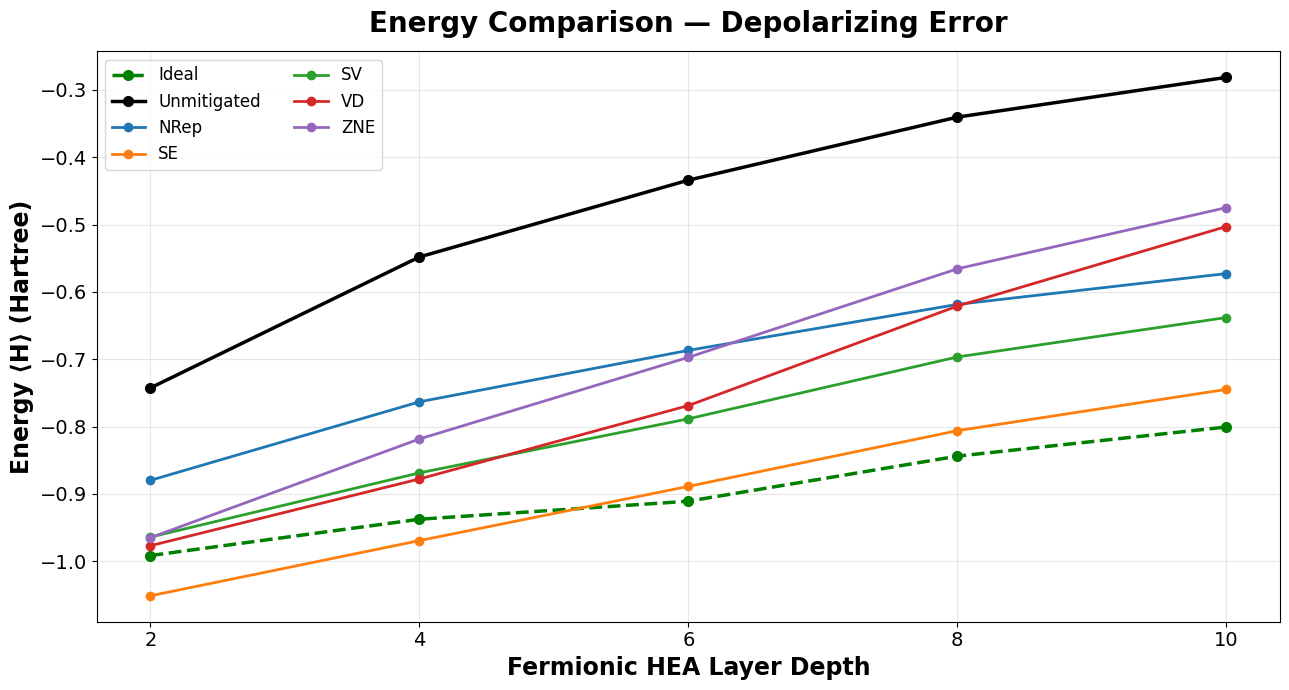

Saved: indi_noise_results/depolarizing_error_energy_comparison.png


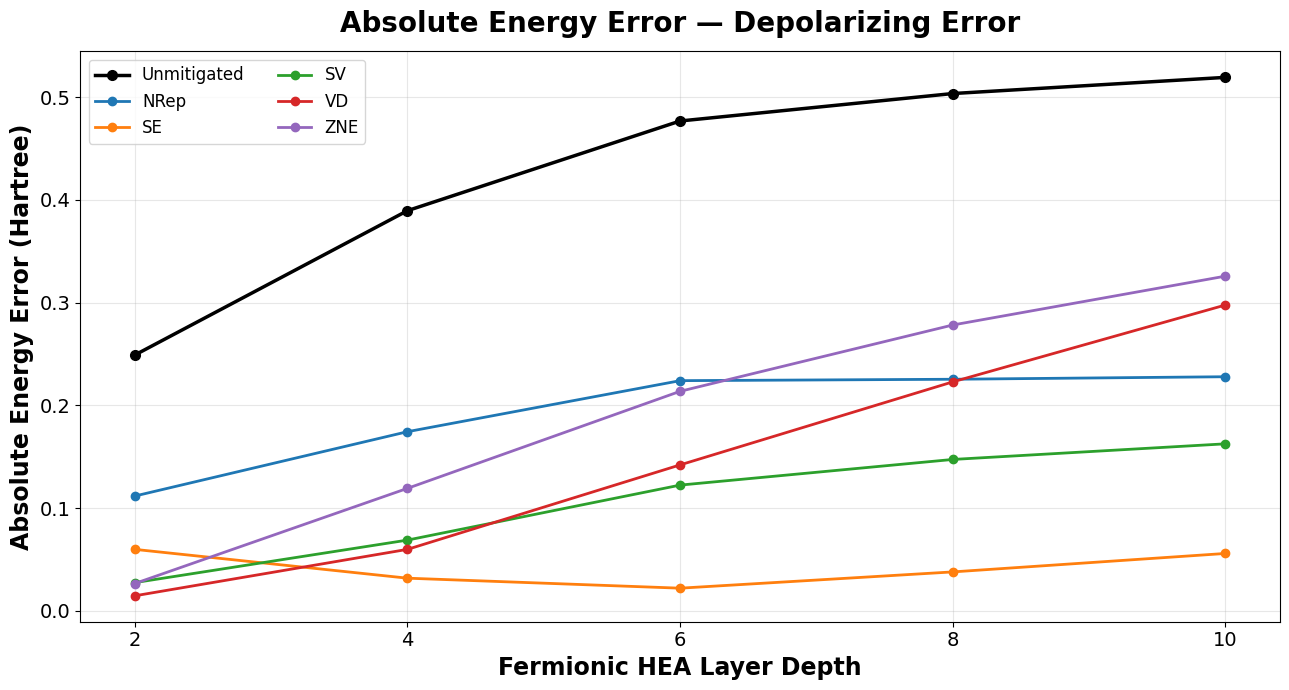

Saved: indi_noise_results/depolarizing_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: BIT FLIP ERROR
###########################################################################


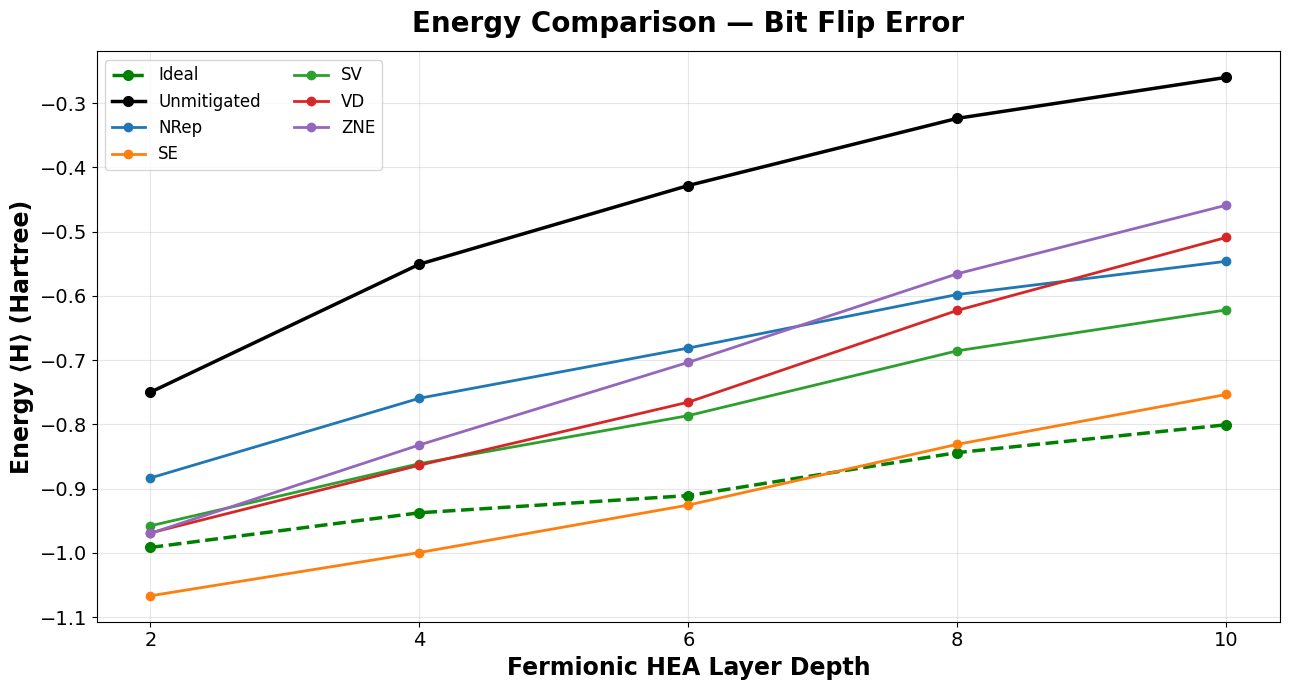

Saved: indi_noise_results/bit_flip_error_energy_comparison.png


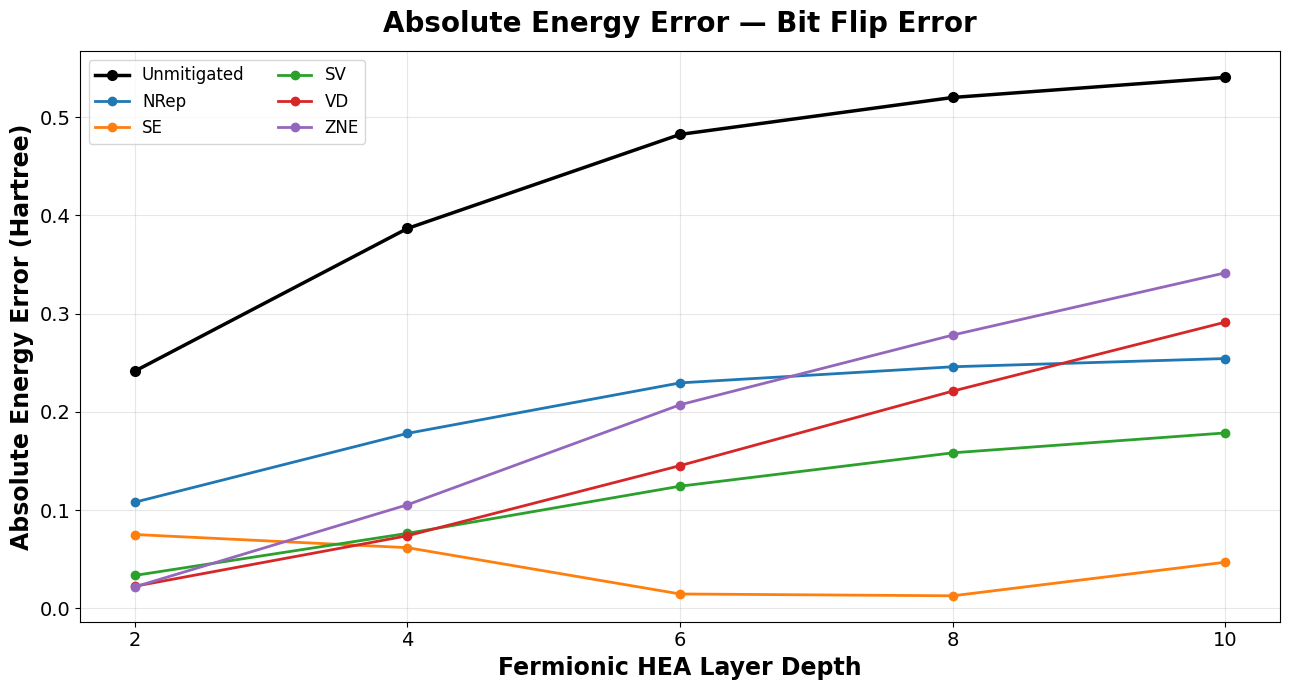

Saved: indi_noise_results/bit_flip_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: PHASE FLIP ERROR
###########################################################################


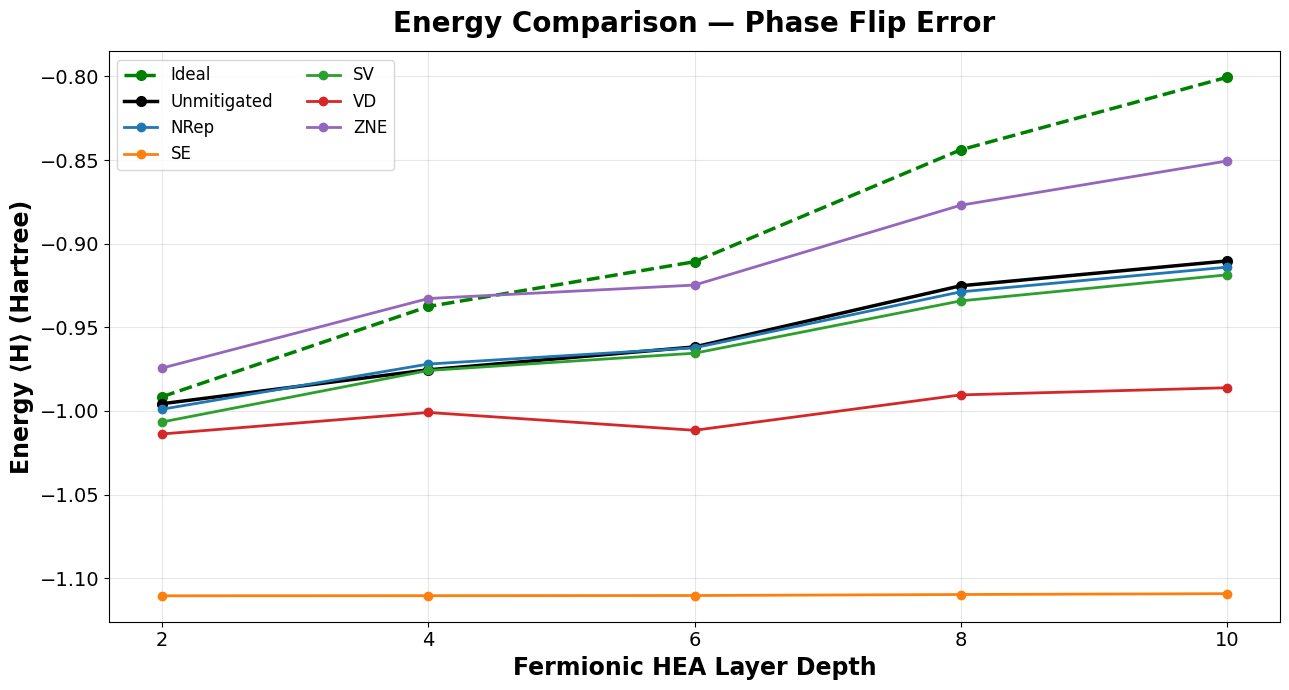

Saved: indi_noise_results/phase_flip_error_energy_comparison.png


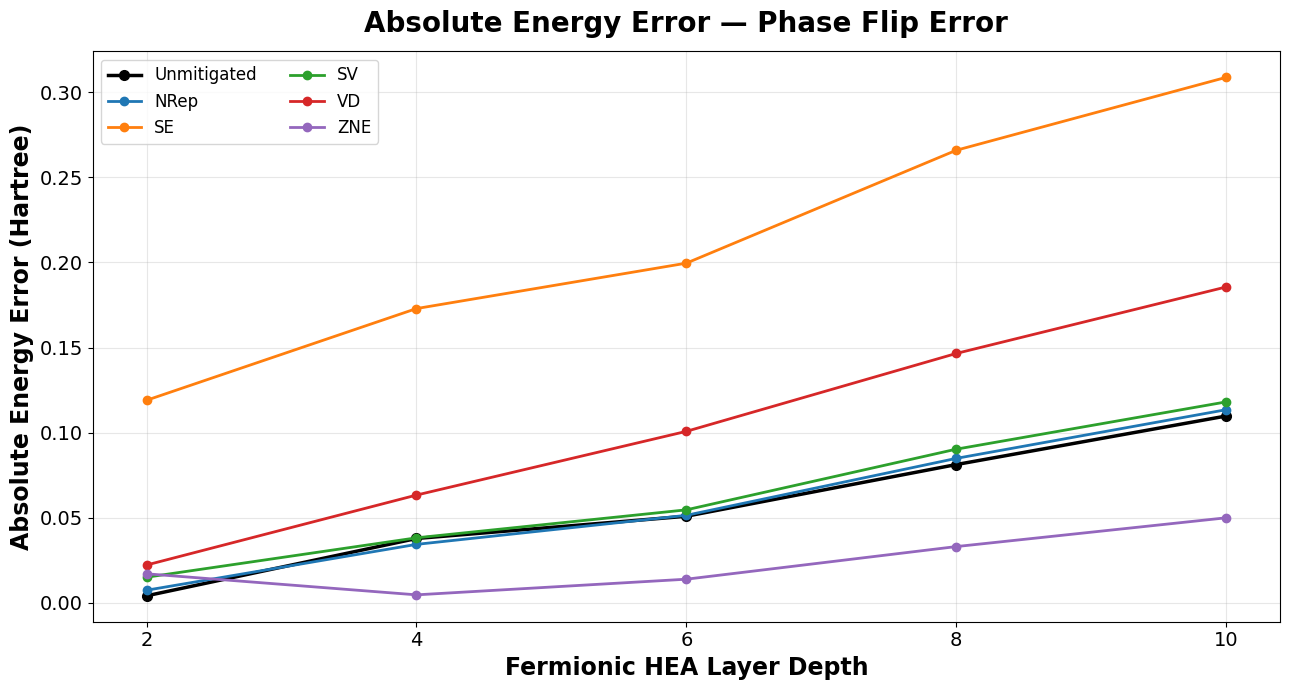

Saved: indi_noise_results/phase_flip_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: BIT PHASE FLIP ERROR
###########################################################################


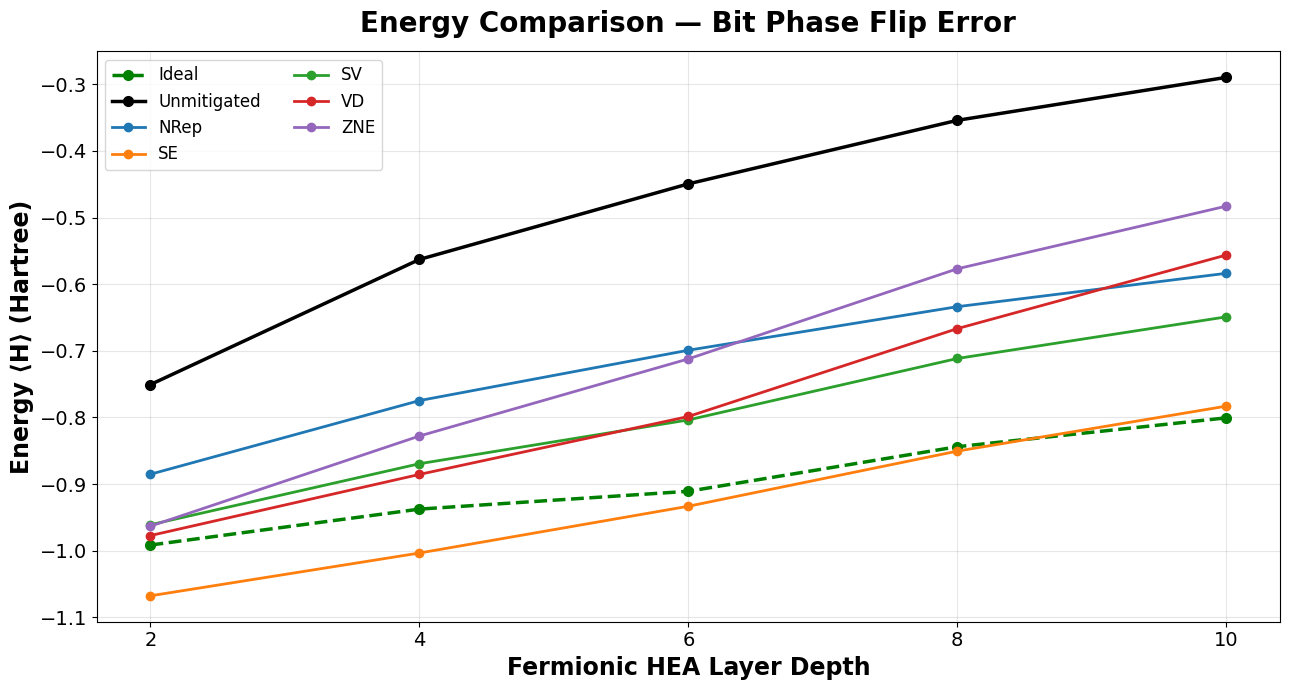

Saved: indi_noise_results/bit_phase_flip_error_energy_comparison.png


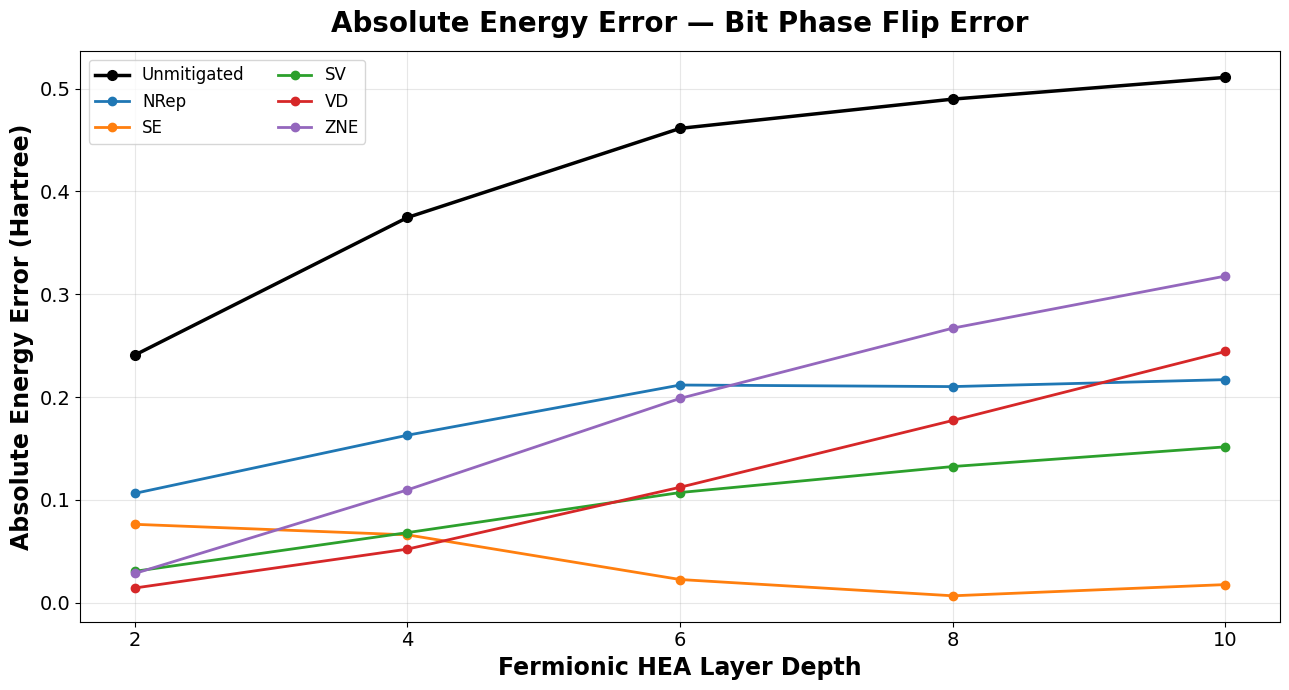

Saved: indi_noise_results/bit_phase_flip_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: PAULI ERROR
###########################################################################


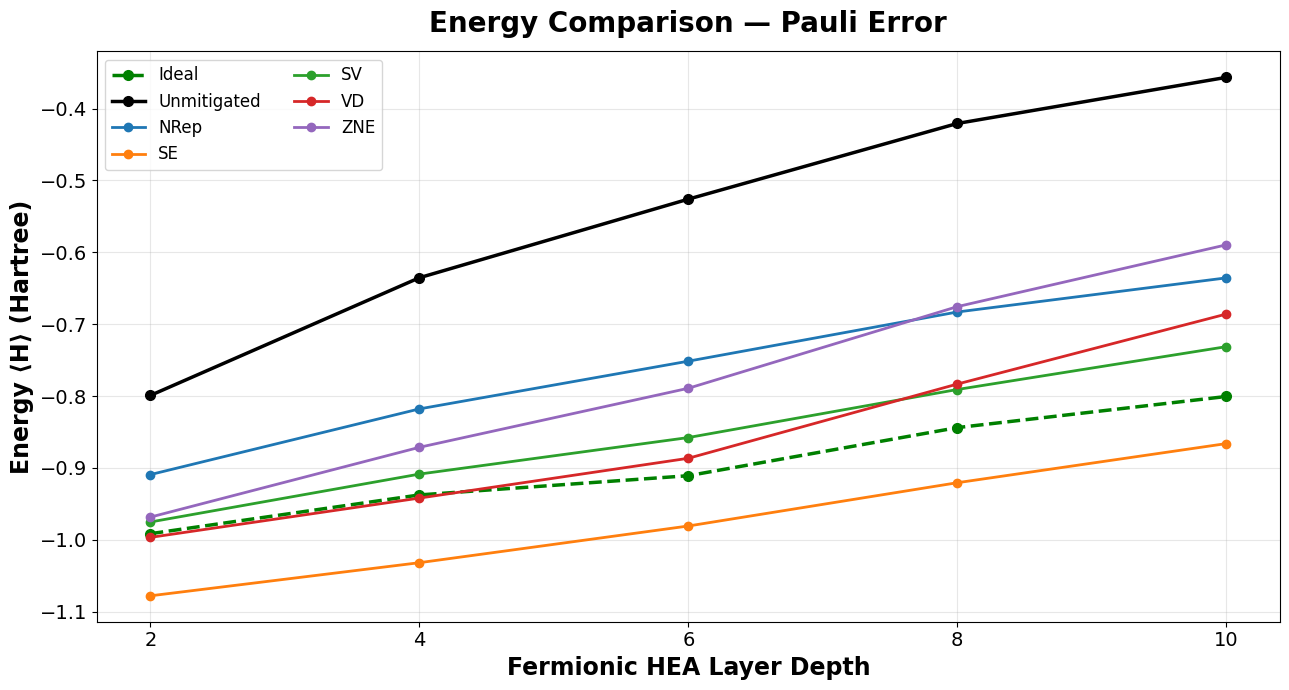

Saved: indi_noise_results/pauli_error_energy_comparison.png


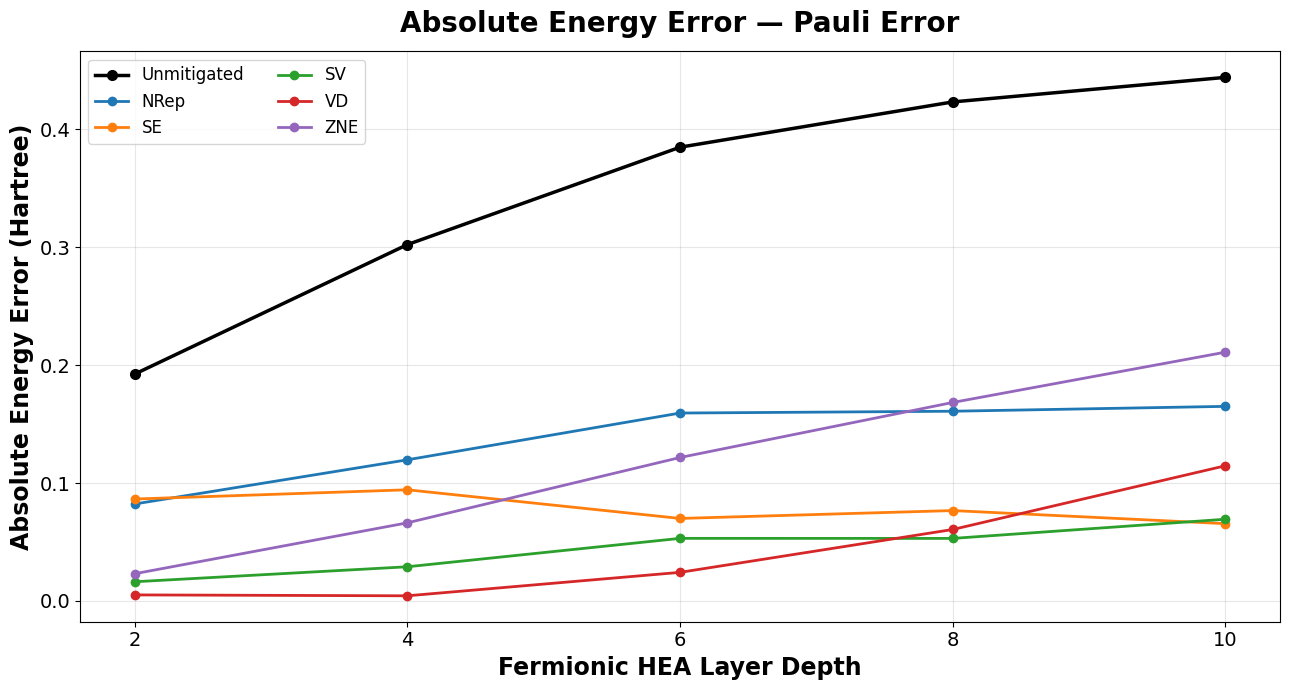

Saved: indi_noise_results/pauli_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: TWO QUBIT DEPOLARIZING ERROR
###########################################################################


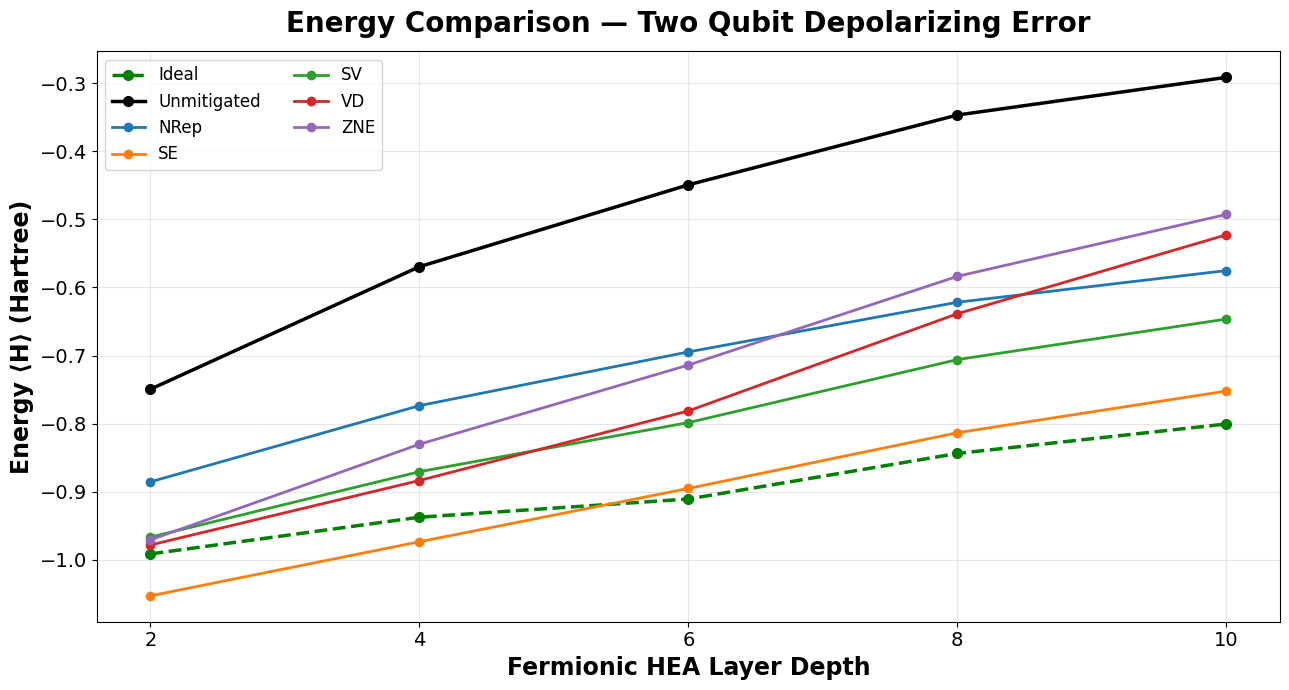

Saved: indi_noise_results/two_qubit_depolarizing_error_energy_comparison.png


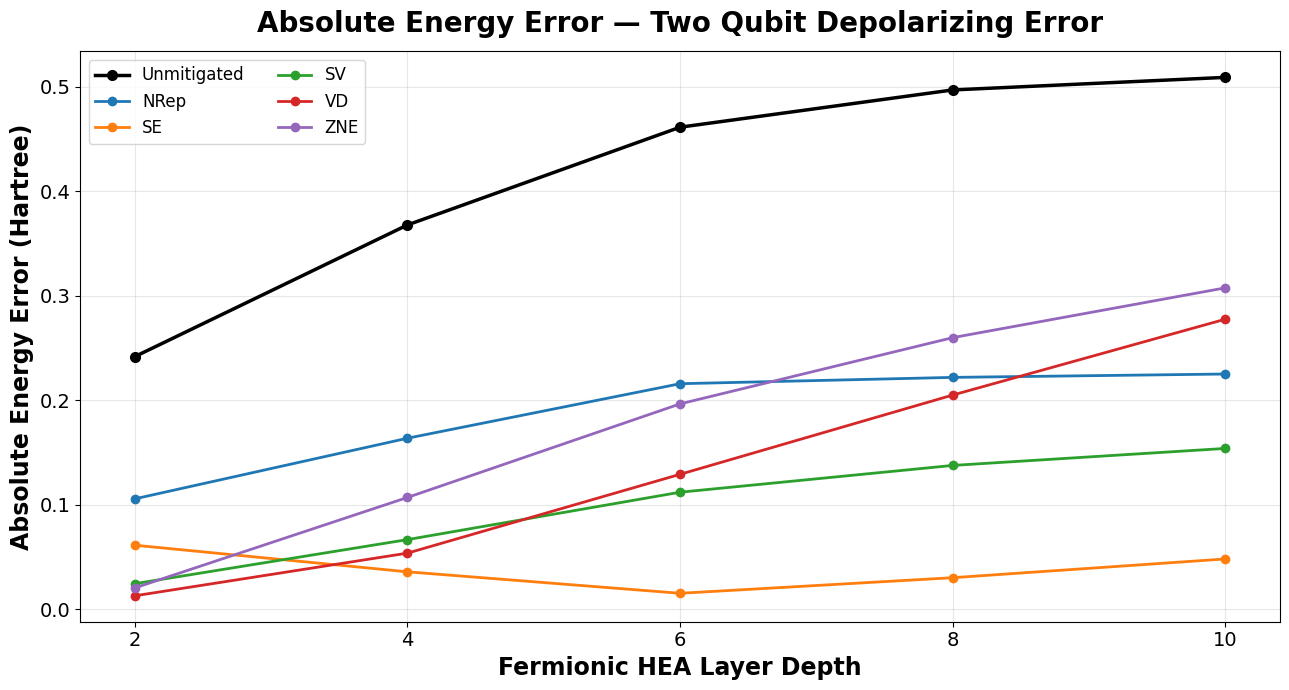

Saved: indi_noise_results/two_qubit_depolarizing_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: TWO QUBIT PAULI ERROR
###########################################################################


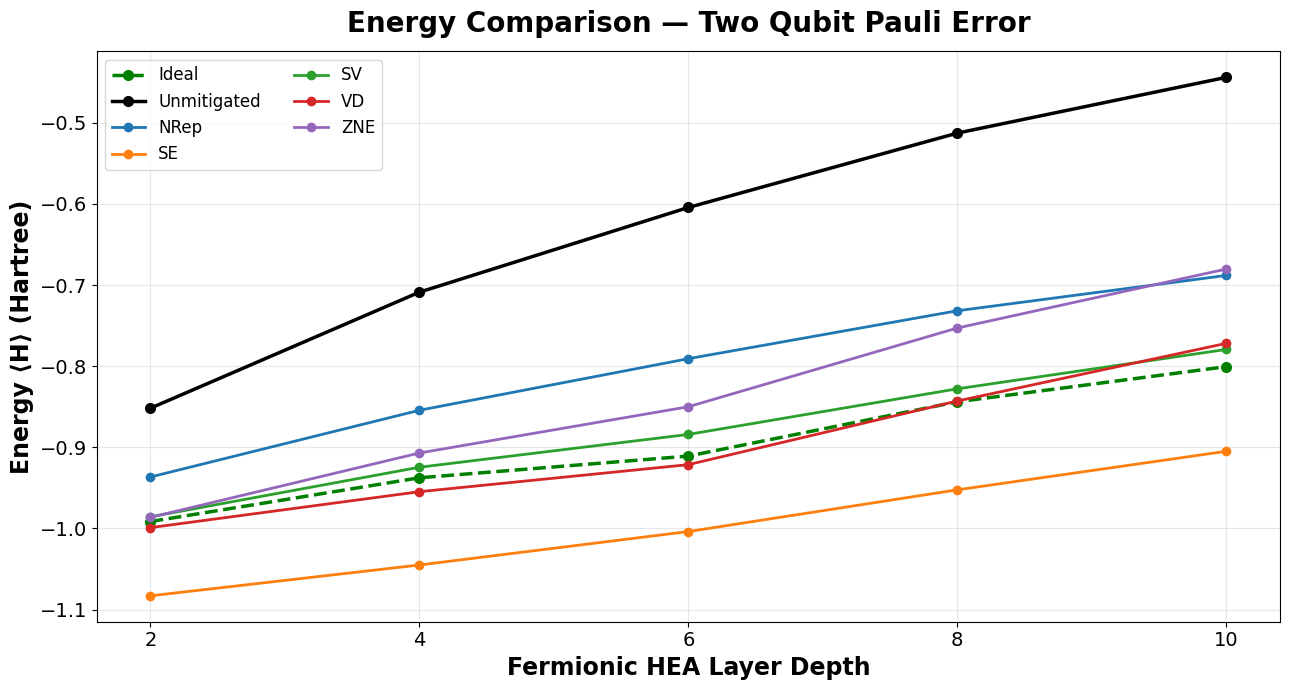

Saved: indi_noise_results/two_qubit_pauli_error_energy_comparison.png


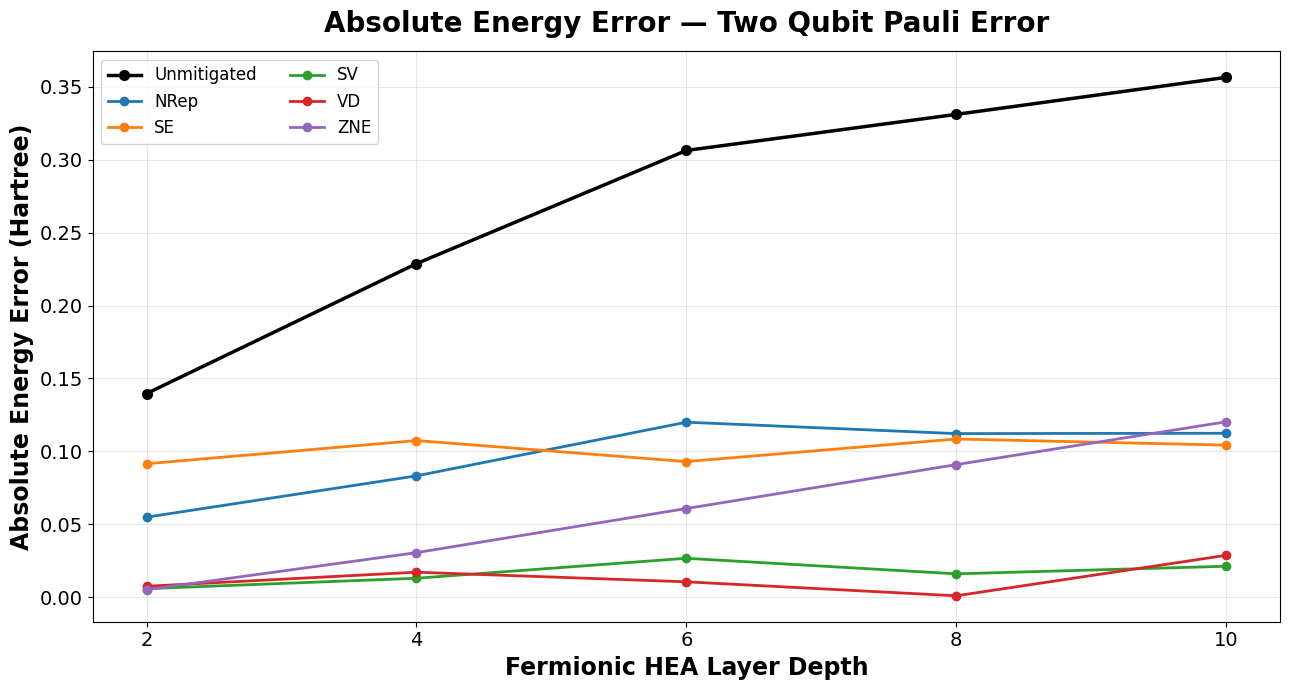

Saved: indi_noise_results/two_qubit_pauli_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: CORRELATED PAULI ERROR
###########################################################################


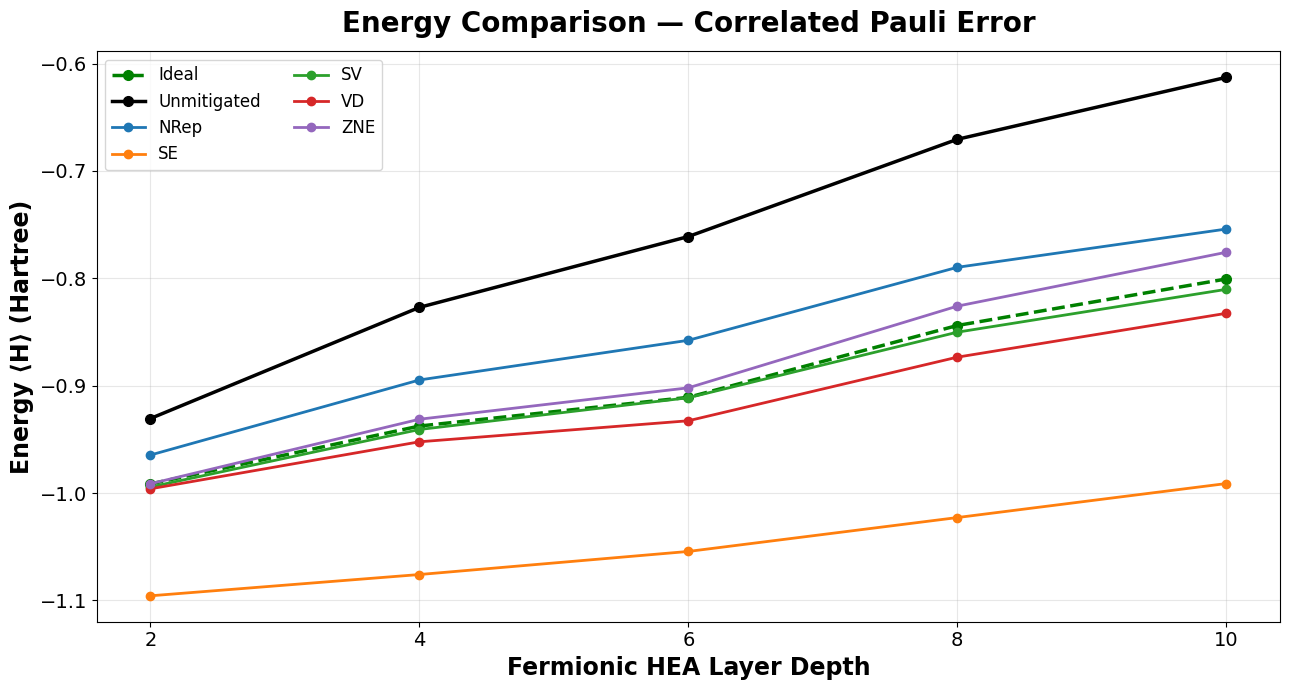

Saved: indi_noise_results/correlated_pauli_error_energy_comparison.png


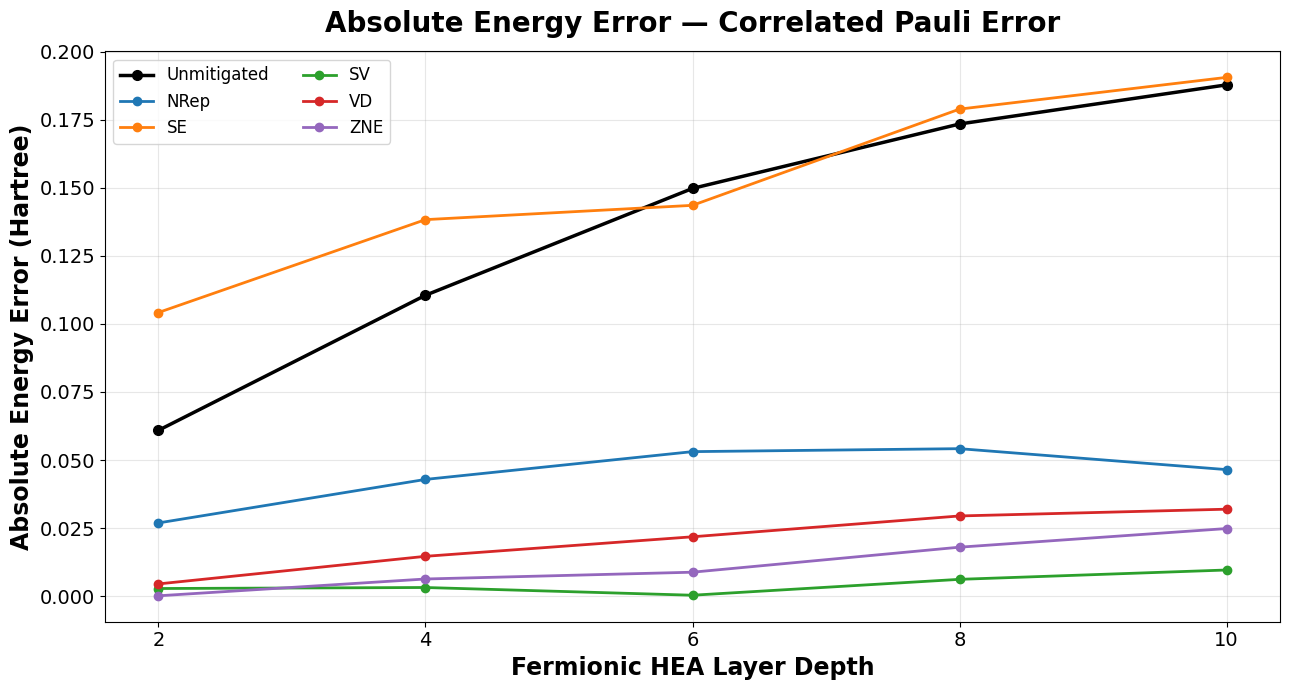

Saved: indi_noise_results/correlated_pauli_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: AMPLITUDE DAMPING ERROR
###########################################################################


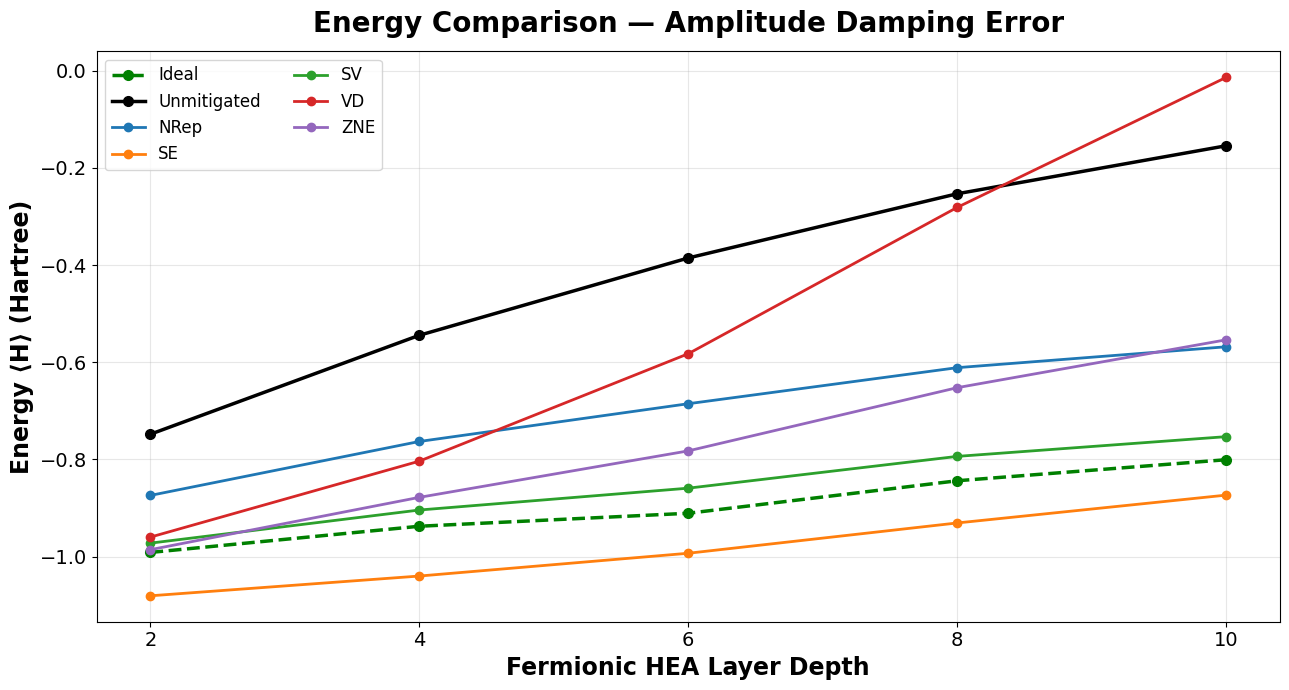

Saved: indi_noise_results/amplitude_damping_error_energy_comparison.png


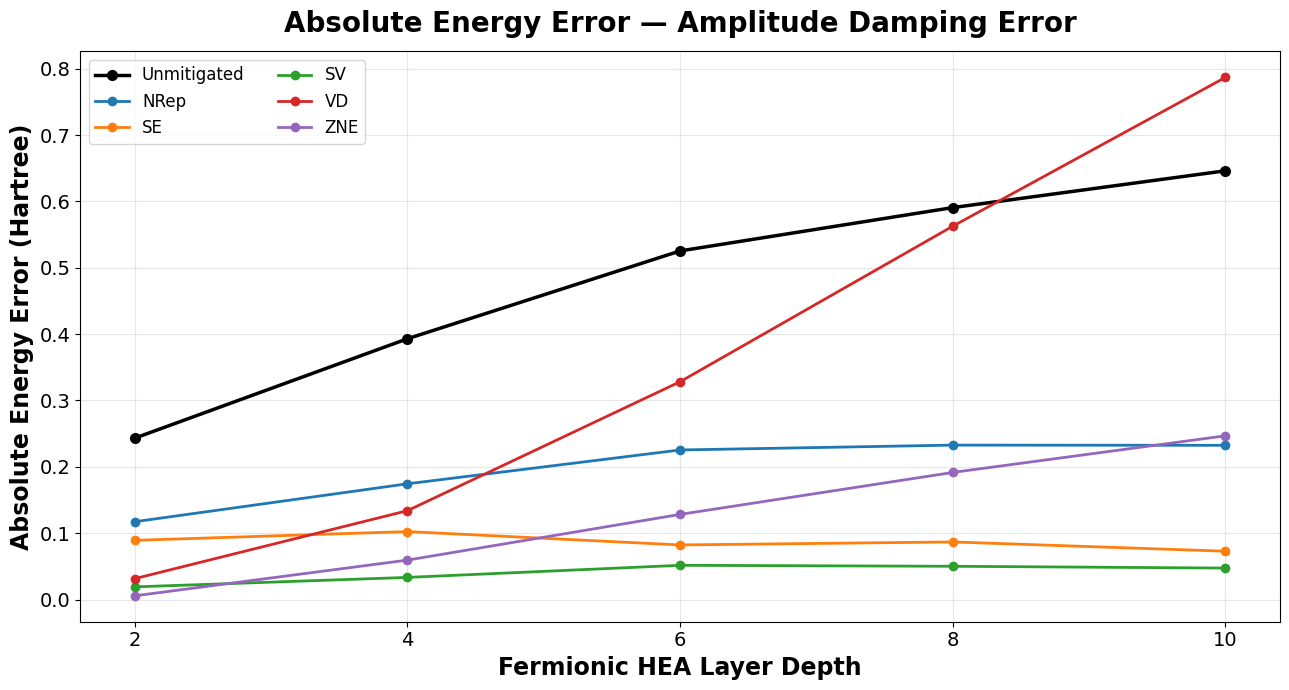

Saved: indi_noise_results/amplitude_damping_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: PHASE DAMPING ERROR
###########################################################################


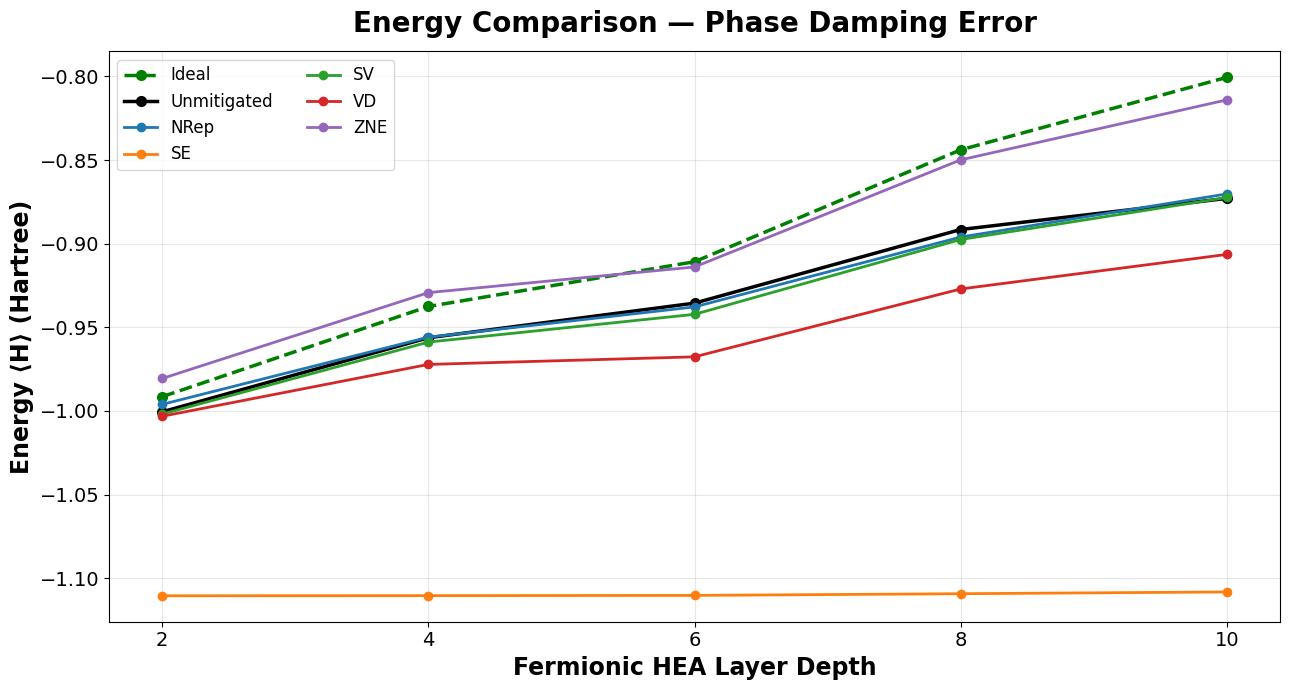

Saved: indi_noise_results/phase_damping_error_energy_comparison.png


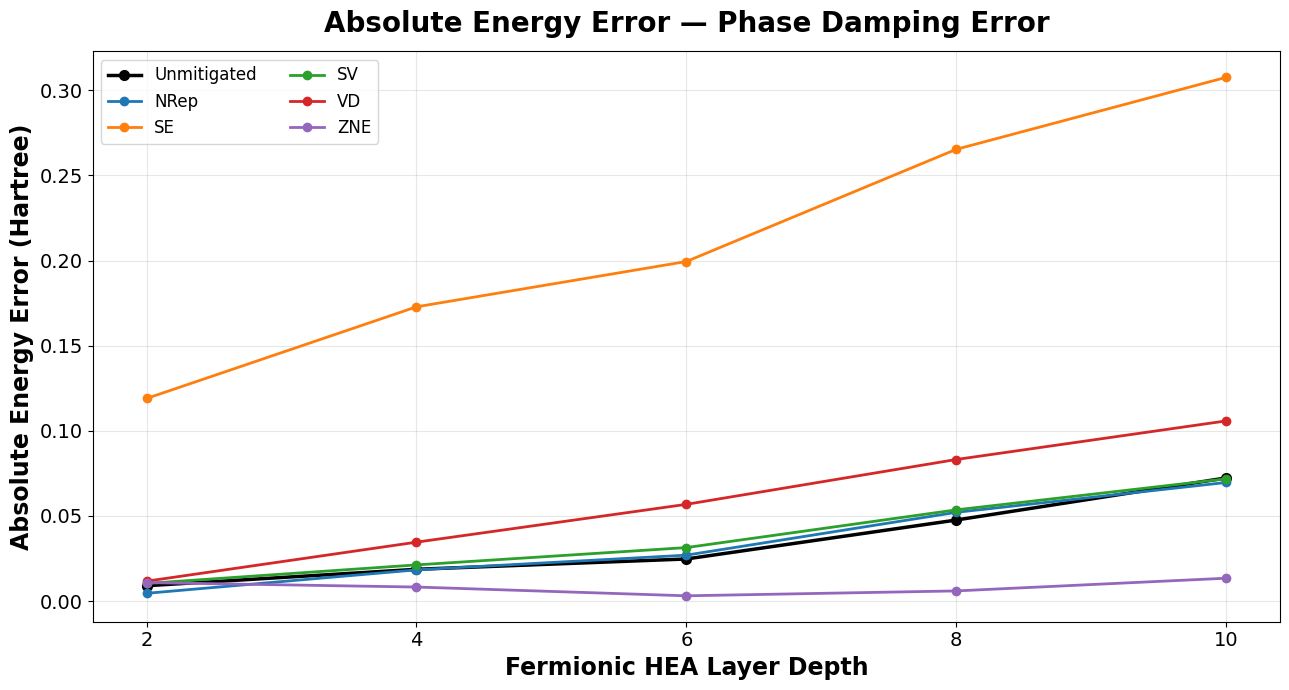

Saved: indi_noise_results/phase_damping_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: GENERALIZED AMPLITUDE DAMPING ERROR
###########################################################################


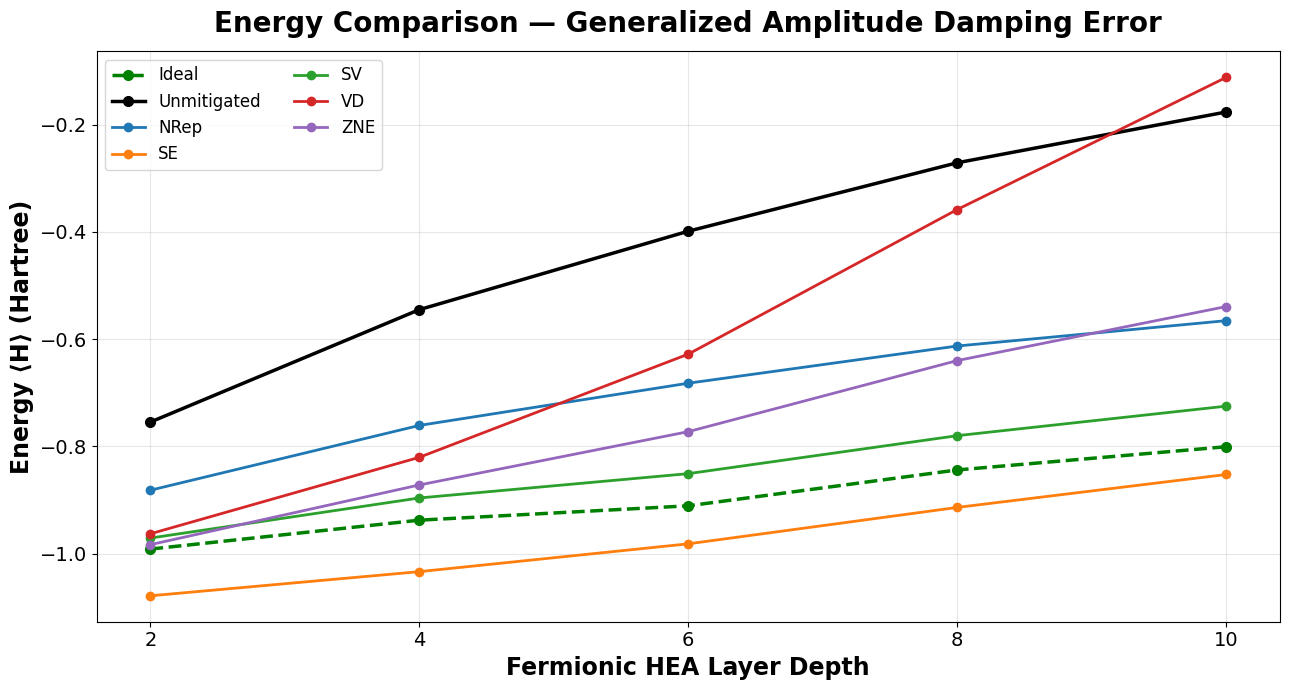

Saved: indi_noise_results/generalized_amplitude_damping_error_energy_comparison.png


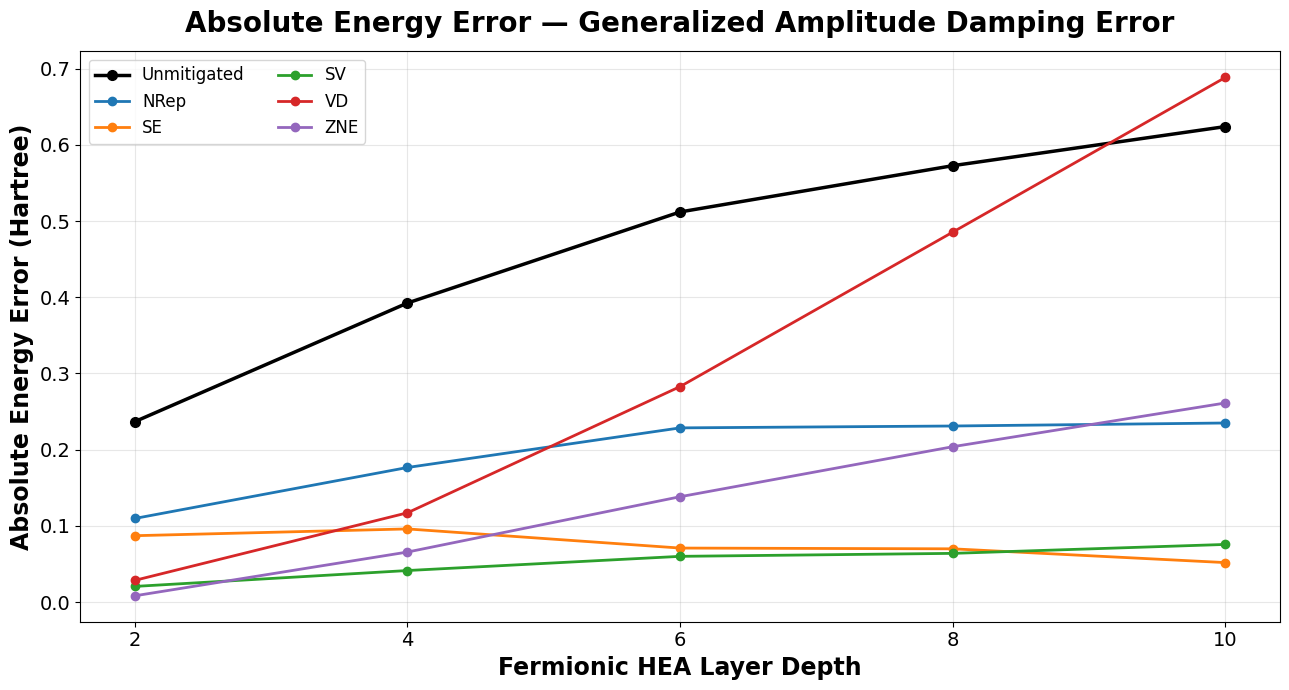

Saved: indi_noise_results/generalized_amplitude_damping_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: THERMAL ERROR
###########################################################################


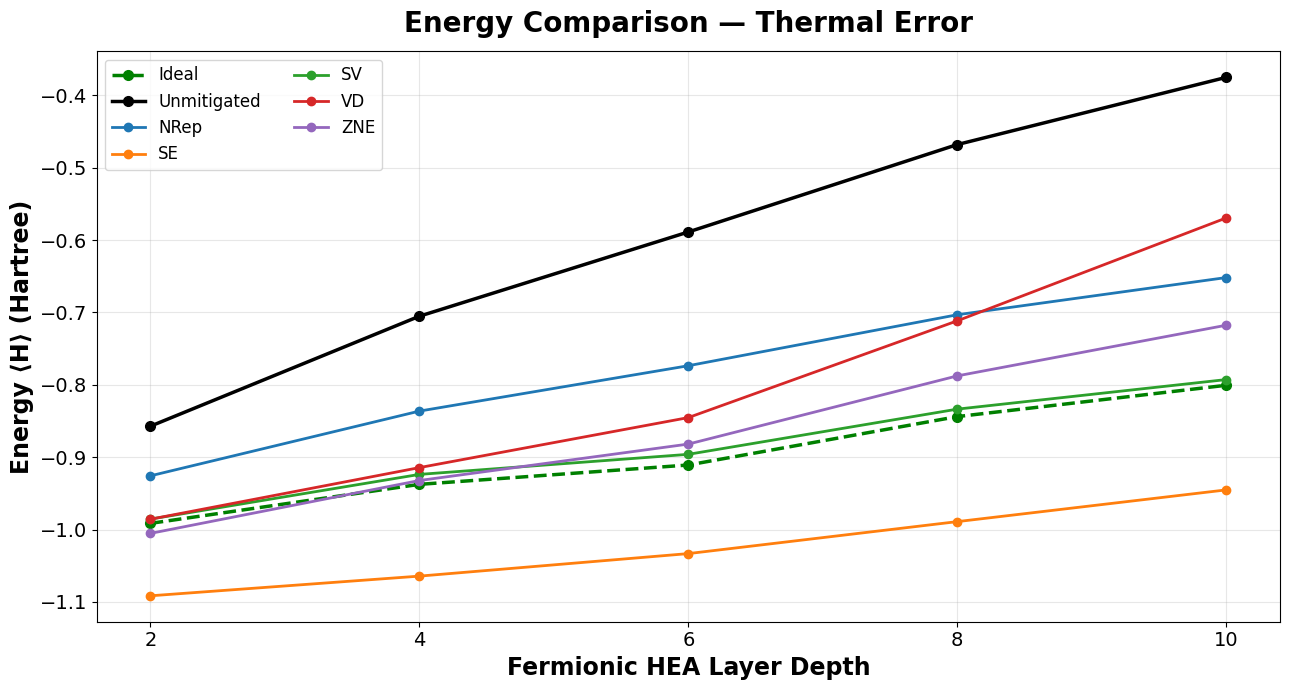

Saved: indi_noise_results/thermal_error_energy_comparison.png


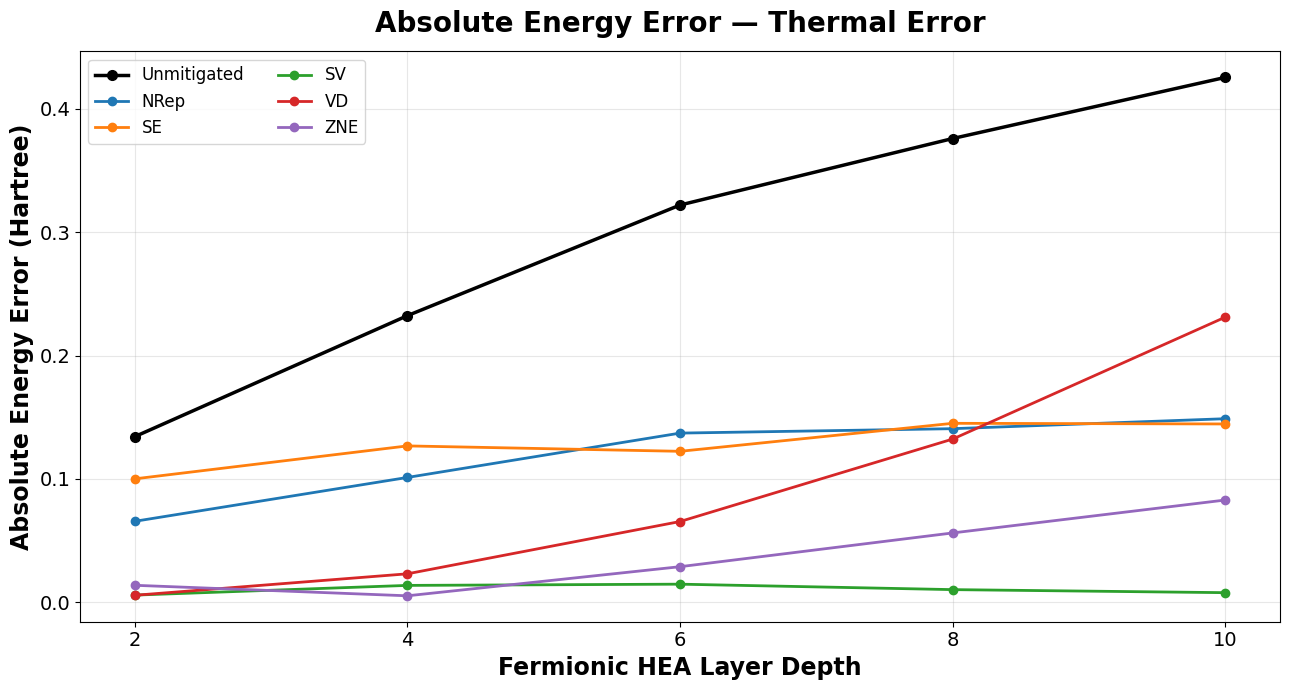

Saved: indi_noise_results/thermal_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: COHERENT ERROR
###########################################################################


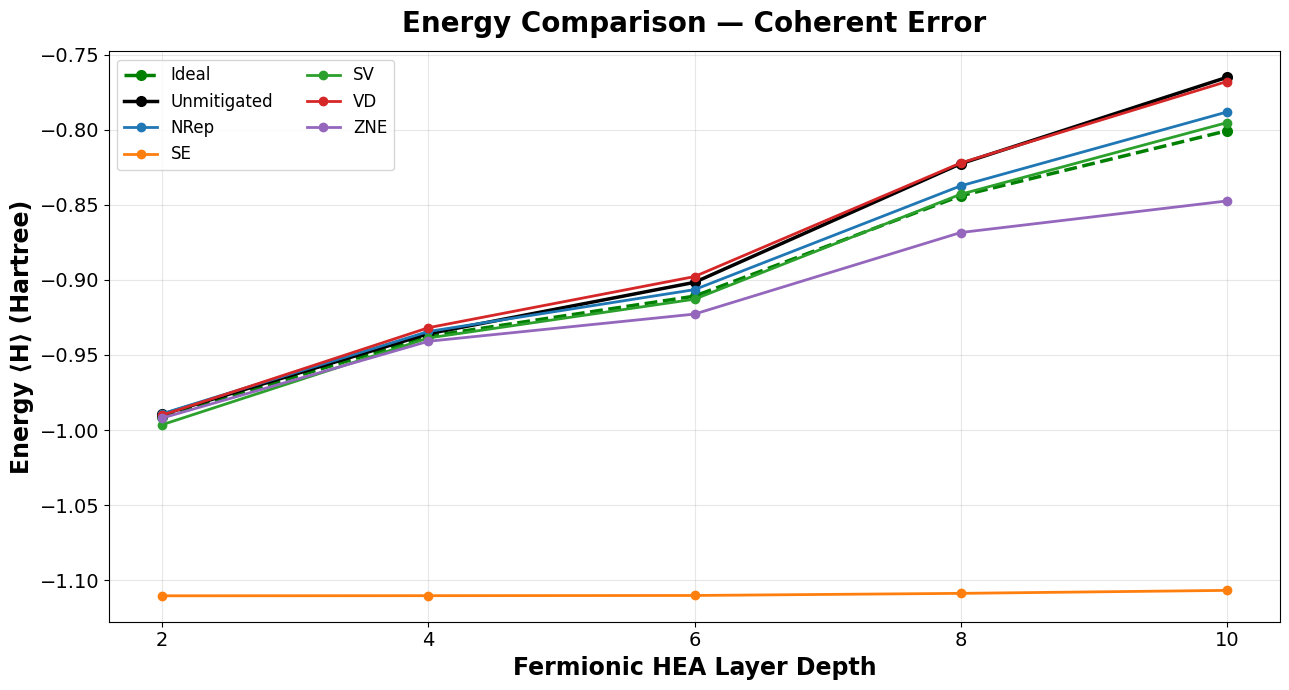

Saved: indi_noise_results/coherent_error_energy_comparison.png


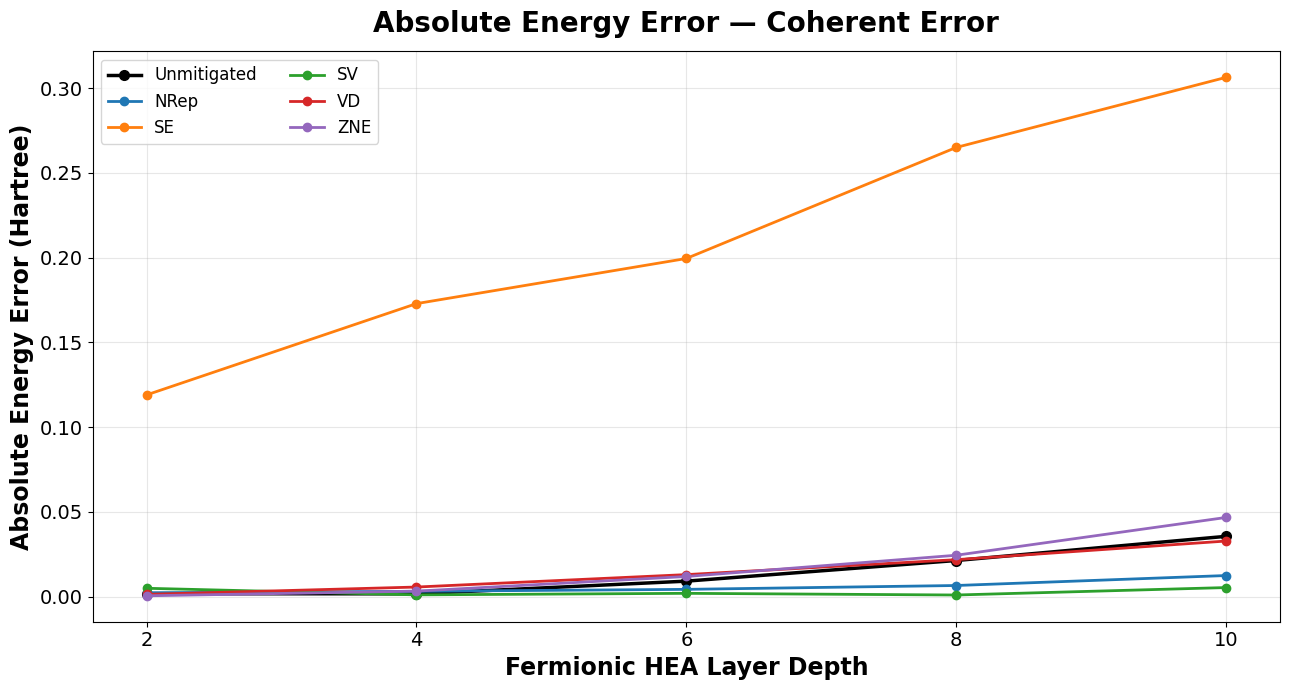

Saved: indi_noise_results/coherent_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: GATE DEPENDENT ERROR
###########################################################################


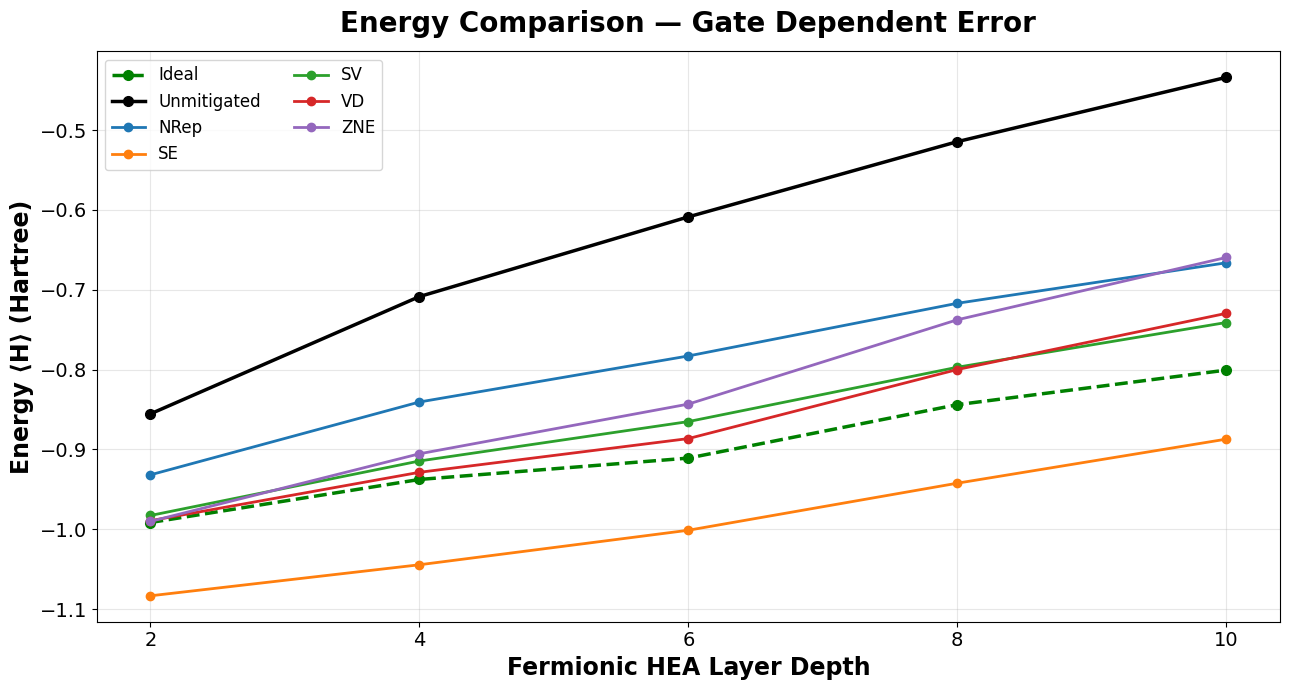

Saved: indi_noise_results/gate_dependent_error_energy_comparison.png


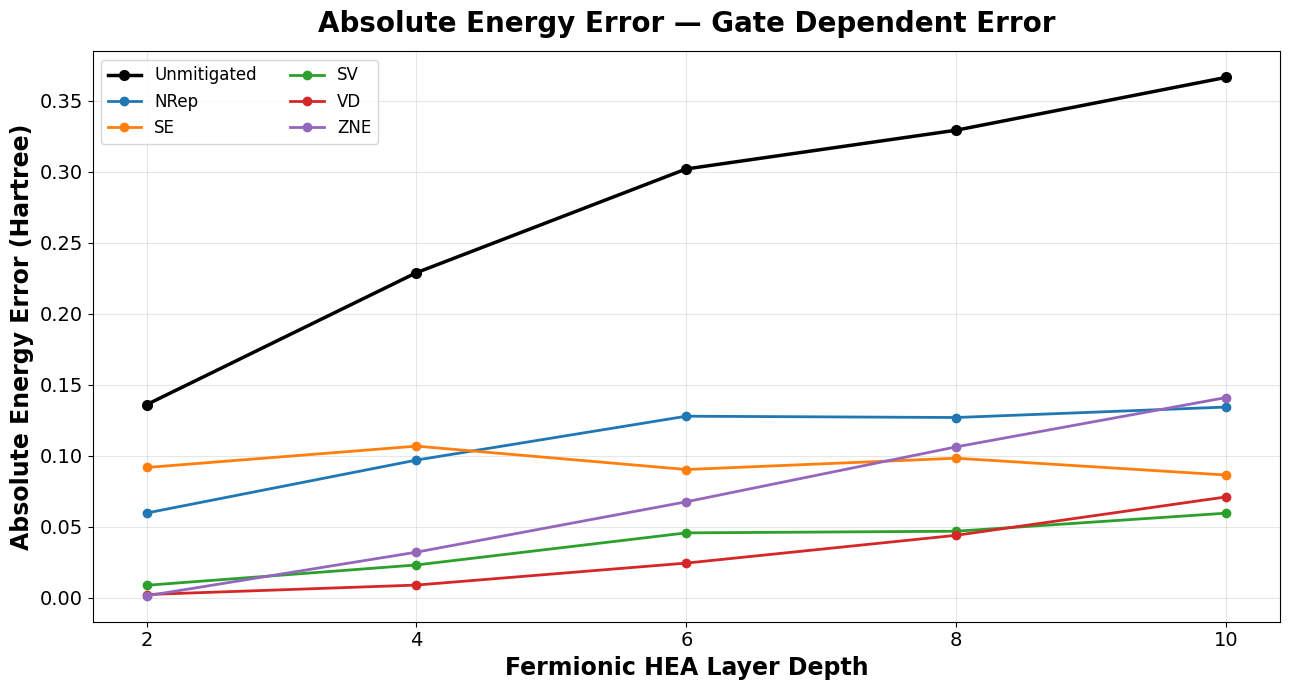

Saved: indi_noise_results/gate_dependent_error_absolute_energy_error.png
\n###########################################################################
GRAPHS FOR: ZZ CROSSTALK ERROR
###########################################################################


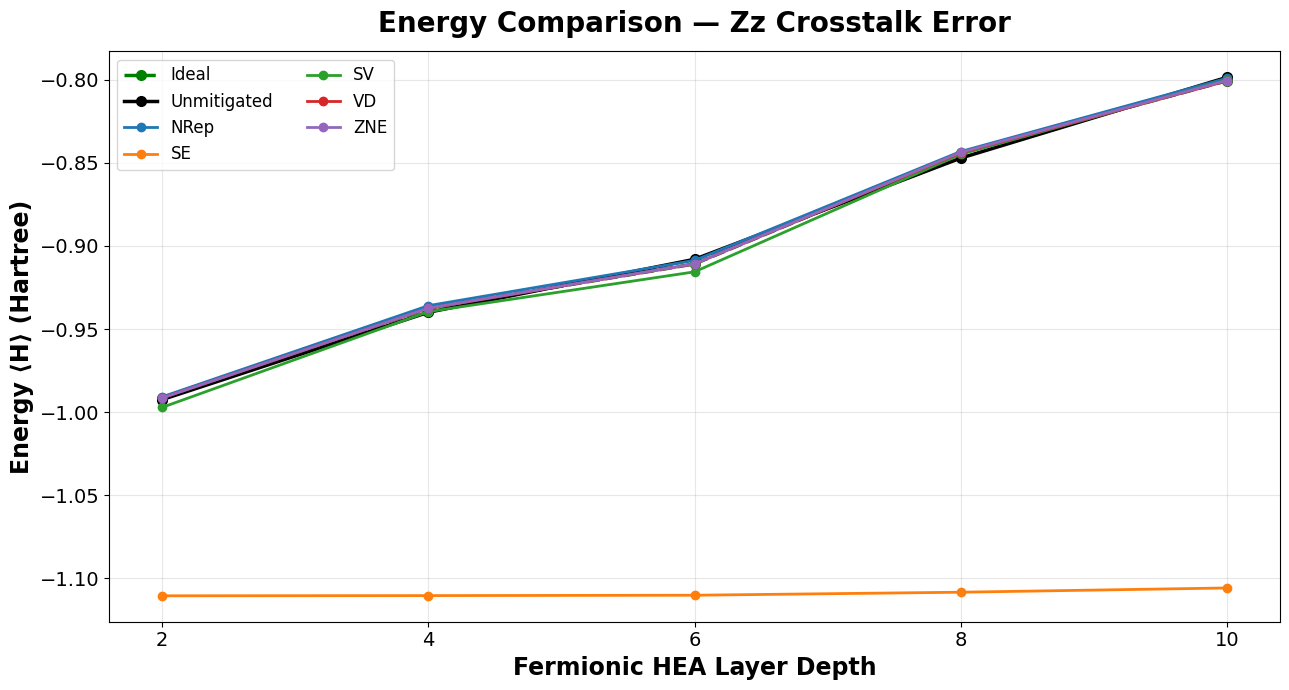

Saved: indi_noise_results/zz_crosstalk_error_energy_comparison.png


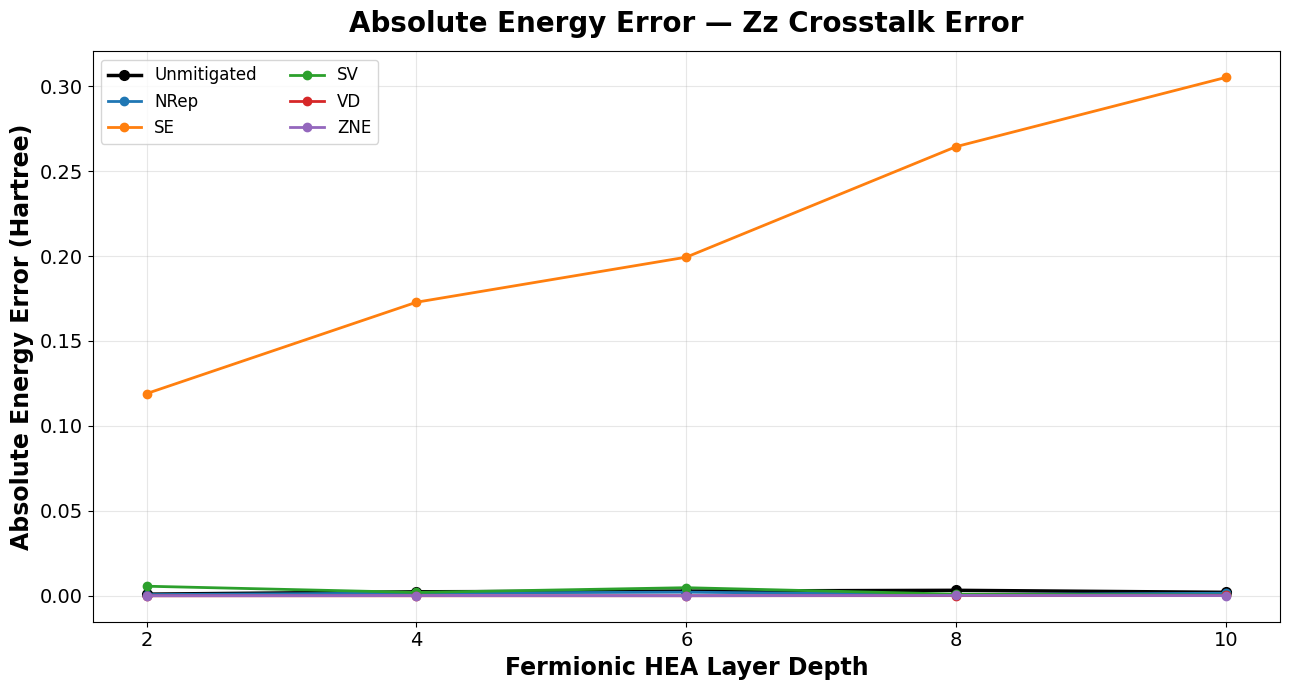

Saved: indi_noise_results/zz_crosstalk_error_absolute_energy_error.png


In [9]:
import os
from pathlib import Path

RESULTS_DIR = Path("indi_noise_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def error_label(error_name):
    return error_name.replace("_", " ").title()

def plot_energy_for_error(df, error_name):
    if df.empty:
        print(f"No successful results for {error_label(error_name)} error.")
        return

    fig, ax = plt.subplots(figsize=(13, 7))

    ref = (
        df[["depth", "ideal"]]
        .drop_duplicates("depth")
        .sort_values("depth")
    )
    ax.plot(
        ref["depth"], ref["ideal"], "o--",
        color="green", label="Ideal", linewidth=2.5, markersize=7
    )

    raw = (
        df[["depth", "noisy"]]
        .dropna()
        .drop_duplicates("depth")
        .sort_values("depth")
    )
    if not raw.empty:
        ax.plot(
            raw["depth"], raw["noisy"], "o-",
            color="black", label="Unmitigated", linewidth=2.5, markersize=7
        )

    for method in df["method"].drop_duplicates():
        d = df[df["method"] == method].sort_values("depth")
        ax.plot(
            d["depth"], d["energy"], "o-",
            label=method, linewidth=2.0, markersize=6
        )

    ax.set_xlabel("Fermionic HEA Layer Depth", fontsize=17, fontweight="bold")
    ax.set_ylabel("Energy ⟨H⟩ (Hartree)", fontsize=17, fontweight="bold")
    ax.set_title(
        f"Energy Comparison — {error_label(error_name)} Error",
        fontsize=20, fontweight="bold", pad=14
    )
    ax.tick_params(axis="both", labelsize=14)
    ax.set_xticks(sorted(df["depth"].unique()))
    ax.grid(alpha=0.3)
    ax.legend(ncol=2, fontsize=12)
    fig.tight_layout()

    filename = RESULTS_DIR / f"{error_name}_error_energy_comparison.png"
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {filename}")


def plot_absolute_error_for_error(df, error_name):
    if df.empty:
        print(f"No successful results for {error_label(error_name)} error.")
        return

    fig, ax = plt.subplots(figsize=(13, 7))

    raw = (
        df[["depth", "ideal", "noisy"]]
        .dropna()
        .drop_duplicates("depth")
        .sort_values("depth")
    )
    if not raw.empty:
        ax.plot(
            raw["depth"], np.abs(raw["noisy"] - raw["ideal"]),
            "o-", color="black", label="Unmitigated",
            linewidth=2.5, markersize=7
        )

    for method in df["method"].drop_duplicates():
        d = df[df["method"] == method].sort_values("depth")
        ax.plot(
            d["depth"], np.abs(d["energy"] - d["ideal"]),
            "o-", label=method, linewidth=2.0, markersize=6
        )

    ax.set_xlabel("Fermionic HEA Layer Depth", fontsize=17, fontweight="bold")
    ax.set_ylabel("Absolute Energy Error (Hartree)", fontsize=17, fontweight="bold")
    ax.set_title(
        f"Absolute Energy Error — {error_label(error_name)} Error",
        fontsize=20, fontweight="bold", pad=14
    )
    ax.tick_params(axis="both", labelsize=14)
    ax.set_xticks(sorted(df["depth"].unique()))
    ax.grid(alpha=0.3)
    ax.legend(ncol=2, fontsize=12)
    fig.tight_layout()

    filename = RESULTS_DIR / f"{error_name}_error_absolute_energy_error.png"
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {filename}")


if results_df.empty:
    print("No results available to plot.")
else:
    for error_name in NOISE_CONFIGS:
        if error_name == "readout":
            continue

        error_df = results_df[results_df["noise_type"] == error_name].copy()
        if error_df.empty:
            print(f"Skipping {error_label(error_name)} error: no successful results.")
            continue

        print("\\n" + "#" * 75)
        print(f"GRAPHS FOR: {error_label(error_name).upper()} ERROR")
        print("#" * 75)

        plot_energy_for_error(error_df, error_name)
        plot_absolute_error_for_error(error_df, error_name)

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd

RESULTS_DIR = Path("indi_noise_results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if results_df.empty:
    print("No results available to export.")
else:
    thesis_results = results_df[results_df["noise_type"] != "readout"].copy()
    thesis_results["absolute_energy_error"] = np.abs(
        thesis_results["energy"] - thesis_results["ideal"]
    )

    thesis_results.to_csv(
        RESULTS_DIR / "individual_error_qem_results.csv", index=False
    )

    summary_rows = []
    for error_name, error_df in thesis_results.groupby("noise_type", sort=False):
        expected_depths = error_df["depth"].nunique()
        method_scores = (
            error_df.groupby("method")
            .agg(
                mean_absolute_error=("absolute_energy_error", "mean"),
                depth_count=("depth", "nunique")
            )
            .reset_index()
        )

        complete = method_scores[method_scores["depth_count"] == expected_depths]
        candidates = complete if not complete.empty else method_scores
        best = candidates.sort_values("mean_absolute_error").iloc[0]

        summary_rows.append({
            "Error": error_name.replace("_", " ").title(),
            "Best-performing QEM method": best["method"],
            "Mean absolute energy error (Hartree)": best["mean_absolute_error"]
        })

    thesis_summary = pd.DataFrame(summary_rows).sort_values("Error").reset_index(drop=True)
    thesis_summary.to_csv(
        RESULTS_DIR / "best_method_by_individual_error.csv", index=False
    )

    display(thesis_summary)
    print(f"Saved detailed results: {RESULTS_DIR / 'individual_error_qem_results.csv'}")
    print(f"Saved thesis summary: {RESULTS_DIR / 'best_method_by_individual_error.csv'}")

,Error,Best-performing QEM method,Mean absolute energy error (Hartree)
0,Amplitude Damping,SV,0.040360
1,Bit Flip,SE,0.042358
2,Bit Phase Flip,SE,0.037744
3,Coherent,SV,0.002914
4,Correlated Pauli,SV,0.004464
5,Depolarizing,SE,0.041451
6,Gate Dependent,VD,0.030152
7,Generalized Amplitude Damping,SV,0.052294
8,Pauli,VD,0.041799
9,Phase Damping,ZNE,0.008351


Saved detailed results: indi_noise_results/individual_error_qem_results.csv
Saved thesis summary: indi_noise_results/best_method_by_individual_error.csv
